<a href="https://colab.research.google.com/github/Angeltt251/Mineria-de-Datos/blob/main/CRISP_DM_Churn_Telco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Angeltt251/Mineria-de-Datos/blob/main/Actividad_2_13_CRISP-DM_Churn_Telco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción temprana de fuga de clientes (Customer Churn) en servicios de telecomunicaciones

**Minería de Datos (IEI097) · Unidad II · Actividad 2.13 — Proyecto final · Metodología CRISP-DM**

**Autores:** Bastián Fernández · Miguel Chura · José Flores — Instituto Profesional Santo Tomás

**Tipo de actividad:** notebook de desarrollo del proyecto (continuación del Informe de Planificación entregado el 20-nov-2026)

**Dataset:** Telco Customer Churn (IBM Sample Data Sets, 2018) · [Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) · archivo `WA_Fn-UseC_-Telco-Customer-Churn.csv`

---

## Contenido

| Fase CRISP-DM | Qué se hace | Sección |
|---|---|---|
| 1 · Comprensión del negocio | Problema, objetivo y criterios de éxito | Fase 1 |
| 2 · Comprensión de los datos | Carga, calidad y análisis exploratorio con gráficos | Fase 2 |
| 3 · Preparación de los datos | Limpieza, partición estratificada y pipeline sin fuga de datos | Fase 3 |
| 4 · Modelado | Baseline, tres modelos, validación cruzada, ajuste de hiperparámetros y de umbral | Fase 4 |
| 5 · Evaluación | Métricas en prueba, contraste de hipótesis, importancia de variables y equidad | Fase 5 |
| 6 · Despliegue | Función de puntuación de riesgo y curva de ganancia acumulada | Fase 6 |
| Cierre | Conclusiones, limitaciones, ética y referencias | Fase 7 |

**Cómo usarlo:** ejecuta las celdas en orden (`Entorno de ejecución → Ejecutar todo`). Cuando se pida, sube el archivo CSV. Todas las cifras y veredictos del documento se calculan en el propio notebook, por lo que se actualizan solos si cambian los datos o la semilla.

## Fase 0 · Configuración del entorno

Se importan las librerías, se fija la semilla aleatoria (`random_state = 42`, como indica el protocolo de evaluación del informe) y se declaran en un solo lugar todos los **umbrales de éxito** del informe de planificación. Así, cada veredicto posterior compara contra una constante con nombre y no contra un número suelto.

Los colores de los gráficos siguen un criterio fijo en todo el documento: **naranja = clientes que abandonan (Churn = Yes)** y **azul = clientes que permanecen (Churn = No)**.

In [ ]:
import warnings
import textwrap
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import joblib
import sklearn
from scipy.stats import chi2_contingency
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, make_scorer,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42

RECALL_OBJETIVO = 0.78
F1_OBJETIVO = 0.62
MEJORA_RECALL_VS_BASE = 0.25
MEJORA_F1_VS_BASE = 0.15
DETECCION_NEGOCIO = 0.75
PRECISION_NEGOCIO = 0.55
BRECHA_MAXIMA = 0.05
MEJORA_H1_F1 = 0.05
UMBRAL_H2 = 0.40
MEJORA_H2_RECALL = 0.15
MARGEN_RECALL_UMBRAL = 0.02

C = {"churn": "#eb6834", "no": "#2a78d6", "base": "#8a8a85", "lr": "#6250d6",
     "rf": "#1baf7a", "hgb": "#c98500", "tinta": "#0b0b0b", "tinta2": "#52514e",
     "rejilla": "#e3e2de"}
COLOR_MODELO = {"Baseline (Dummy)": C["base"], "Regresión Logística": C["lr"],
                "Random Forest": C["rf"], "Gradient Boosting": C["hgb"]}
CMAP_SEC = LinearSegmentedColormap.from_list("sec", ["#fdf1ea", "#f9c7ab", "#eb6834"])

sns.set_theme(style="white")
mpl.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C["tinta2"], "axes.labelcolor": C["tinta2"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": C["tinta"], "axes.grid": True, "axes.axisbelow": True,
    "grid.color": C["rejilla"], "grid.linewidth": 0.8,
    "xtick.color": C["tinta2"], "ytick.color": C["tinta2"],
    "legend.frameon": False, "font.size": 10,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 140)

def formato_pct(ax, eje="y", decimales=0):
    formateador = mtick.PercentFormatter(1.0, decimals=decimales)
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(formateador)

def etiquetar(ax, formato="{:.1%}", **kwargs):
    for contenedor in ax.containers:
        ax.bar_label(contenedor, labels=[formato.format(v) for v in contenedor.datavalues],
                     padding=3, fontsize=9, color=C["tinta"], **kwargs)

print(f"Python listo · pandas {pd.__version__} · scikit-learn {sklearn.__version__} · semilla = {SEED}")

Python listo · pandas 2.2.3 · scikit-learn 1.6.1 · semilla = 42


# Fase 1 · Comprensión del negocio (Business Understanding)

### Contexto y problema
En telecomunicaciones (telefonía, fibra óptica y servicios complementarios) los mercados son maduros, con alta competencia y portabilidad sencilla. Captar un cliente nuevo suele costar entre 5 y 7 veces más que retener a uno existente, por lo que cada **fuga de clientes (churn)** erosiona los ingresos recurrentes y el valor de largo plazo del cliente.

El problema operativo es que las acciones de retención se activan **tarde**, cuando el cliente ya contactó a la empresa para dar de baja su plan. No existe un mecanismo sistemático que anticipe qué clientes activos tienen alta probabilidad de irse según su contrato, antigüedad, servicios contratados y facturación.

### Objetivo de negocio
Apoyar al área de retención comercial con un **sistema de puntuación de riesgo de fuga** que permita focalizar campañas preventivas (ofertas de fidelización, migración de plan o asistencia técnica dirigida) en los clientes con mayor propensión a abandonar, antes de que soliciten la baja.

### Objetivo de minería de datos
**Clasificación binaria supervisada.** La variable histórica `Churn` (`Yes`/`No`) entrega etiquetas conocidas para entrenar un modelo que estime la clase y la **probabilidad de abandono** de cada cliente a partir de sus características contractuales, demográficas y de consumo.

- **Variable objetivo:** `Churn` codificada como `1` (Yes, abandonó en el último mes) y `0` (No, permaneció).
- **Métrica principal:** *Recall* de la clase `Churn = 1`, porque omitir a un cliente que se va (falso negativo) cuesta más que contactar preventivamente a uno estable (falso positivo). Se respalda con F1-Score, ROC-AUC y PR-AUC.

### Criterios de éxito (definidos en el informe de planificación)

| Nivel | Criterio | Umbral |
|---|---|---|
| Negocio | Detección oportuna: porcentaje de fugas reales identificadas | ≥ 75 % |
| Negocio | Precisión operativa: porcentaje de alertas que son fugas reales | ≥ 55 % |
| Minería de datos | Recall de `Churn = 1` en prueba | ≥ 0,78 |
| Minería de datos | F1-Score de `Churn = 1` en prueba | ≥ 0,62 |
| Minería de datos | Superar al *Dummy Classifier* | ≥ +25 pts de Recall y ≥ +15 pts de F1 |
| Selección | Brecha entre entrenamiento y prueba | ≤ 5 pts |

### Hipótesis a contrastar
- **H1 (no linealidad):** Random Forest y Gradient Boosting superarán a la Regresión Logística en al menos 0,05 de F1-Score, porque el abandono responde a interacciones no lineales entre `Contract`, `tenure` y `MonthlyCharges`.
- **H2 (ponderación y umbral):** usar `class_weight="balanced"` junto con un umbral de 0,40 en lugar de 0,50 permitirá alcanzar un Recall ≥ 0,78, elevando la sensibilidad en al menos 15 puntos frente a un modelo sin ponderación.

Las dos hipótesis se resuelven en la Fase 5 con los datos reales.

# Fase 2 · Comprensión de los datos (Data Understanding)

## 2.1 Carga del dataset

El archivo se sube desde el computador con `files.upload()` y luego se lee desde la ruta fija de Colab (`/content/`). Es el mismo archivo `WA_Fn-UseC_-Telco-Customer-Churn.csv` descrito en el informe (alternativa reproducible: `kagglehub.dataset_download("blastchar/telco-customer-churn")`).

In [ ]:
from google.colab import files
subido = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [ ]:
RUTA_CSV = "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df_raw = pd.read_csv(RUTA_CSV)
print(f"Filas: {df_raw.shape[0]:,} · Columnas: {df_raw.shape[1]}".replace(",", "."))
display(df_raw.head())

Filas: 7.043 · Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2.2 Diccionario de variables

Se resume cada columna con su tipo, cantidad de valores distintos, nulos explícitos y ejemplos. Además se agrega la descripción de negocio definida en el informe. Nótese que `TotalCharges` llega como texto (`object`/`str`) aunque representa un monto: se corregirá en la preparación.

In [ ]:
descripciones = {
    "customerID": "Identificador único del cliente",
    "gender": "Género del cliente",
    "SeniorCitizen": "Adulto mayor (1 = sí, 0 = no)",
    "Partner": "Tiene pareja",
    "Dependents": "Tiene dependientes a cargo",
    "tenure": "Meses de permanencia en la empresa (0 a 72)",
    "PhoneService": "Servicio telefónico activo",
    "MultipleLines": "Múltiples líneas telefónicas",
    "InternetService": "Tecnología de internet (DSL, Fiber optic, No)",
    "OnlineSecurity": "Seguridad en línea",
    "OnlineBackup": "Respaldo en la nube",
    "DeviceProtection": "Protección de dispositivo",
    "TechSupport": "Soporte técnico prioritario",
    "StreamingTV": "Televisión por streaming",
    "StreamingMovies": "Películas por streaming",
    "Contract": "Duración del contrato",
    "PaperlessBilling": "Facturación electrónica sin papel",
    "PaymentMethod": "Medio de pago",
    "MonthlyCharges": "Cargo mensual actual (USD)",
    "TotalCharges": "Monto total acumulado facturado (USD)",
    "Churn": "Abandono en el último mes (variable objetivo)",
}
diccionario = pd.DataFrame({
    "descripción": pd.Series(descripciones),
    "tipo": df_raw.dtypes.astype(str),
    "valores distintos": df_raw.nunique(),
    "nulos": df_raw.isna().sum(),
    "ejemplos": pd.Series({c: ", ".join(map(str, df_raw[c].dropna().unique()[:3])) for c in df_raw.columns}),
})
display(diccionario)

,descripción,tipo,valores distintos,nulos,ejemplos
customerID,Identificador único del cliente,object,7043,0,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK"
gender,Género del cliente,object,2,0,"Female, Male"
SeniorCitizen,"Adulto mayor (1 = sí, 0 = no)",int64,2,0,"0, 1"
Partner,Tiene pareja,object,2,0,"Yes, No"
Dependents,Tiene dependientes a cargo,object,2,0,"No, Yes"
tenure,Meses de permanencia en la empresa (0 a 72),int64,73,0,"1, 34, 2"
PhoneService,Servicio telefónico activo,object,2,0,"No, Yes"
MultipleLines,Múltiples líneas telefónicas,object,3,0,"No phone service, No, Yes"
InternetService,"Tecnología de internet (DSL, Fiber optic, No)",object,3,0,"DSL, Fiber optic, No"
OnlineSecurity,Seguridad en línea,object,3,0,"No, Yes, No internet service"


## 2.3 Diagnóstico de calidad de datos

El informe de planificación afirmó cuatro hechos sobre la calidad del dataset. Antes de construir nada sobre ellos, se **verifican contra los datos reales**: tamaño, valores vacíos ocultos en `TotalCharges`, duplicados y desbalance de clases.

In [ ]:
vacios = df_raw["TotalCharges"].astype(str).str.strip().eq("")
verificacion = pd.DataFrame([
    ("Filas", 7043, len(df_raw)),
    ("Columnas", 21, df_raw.shape[1]),
    ("TotalCharges vacíos (texto en blanco)", 11, int(vacios.sum())),
    ("…de ellos con tenure = 0", 11, int((vacios & df_raw["tenure"].eq(0)).sum())),
    ("Filas duplicadas", 0, int(df_raw.duplicated().sum())),
    ("customerID únicos", 7043, int(df_raw["customerID"].nunique())),
    ("Churn = No", 5174, int((df_raw["Churn"] == "No").sum())),
    ("Churn = Yes", 1869, int((df_raw["Churn"] == "Yes").sum())),
], columns=["indicador", "informe", "observado"])
verificacion["coincide"] = np.where(verificacion["informe"] == verificacion["observado"], "✅", "❌")
display(verificacion)

print("\nClientes con TotalCharges vacío (todos recién ingresados, sin facturación acumulada):")
display(df_raw.loc[vacios, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])

,indicador,informe,observado,coincide
0,Filas,7043,7043,✅
1,Columnas,21,21,✅
2,TotalCharges vacíos (texto en blanco),11,11,✅
3,…de ellos con tenure = 0,11,11,✅
4,Filas duplicadas,0,0,✅
5,customerID únicos,7043,7043,✅
6,Churn = No,5174,5174,✅
7,Churn = Yes,1869,1869,✅



Clientes con TotalCharges vacío (todos recién ingresados, sin facturación acumulada):


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


**Lectura:** los 11 `TotalCharges` vacíos corresponden exactamente a clientes con `tenure = 0`, es decir, clientes que todavía no completan su primer ciclo de facturación. No son datos perdidos por error: el valor correcto es `0.0`. Esa es la regla de imputación que se aplicará en la Fase 3.

Para el análisis exploratorio se trabaja sobre una copia con `TotalCharges` ya convertida a número y `SeniorCitizen` con etiquetas legibles. Esta copia solo sirve para graficar; el pipeline de modelado se construye aparte en la Fase 3.

In [ ]:
df_eda = df_raw.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce").fillna(0.0)
df_eda["SeniorCitizen"] = df_eda["SeniorCitizen"].map({0: "No", 1: "Yes"})
df_eda["churn"] = (df_eda["Churn"] == "Yes").astype(int)
TASA_GLOBAL = df_eda["churn"].mean()
print(f"Tasa global de abandono: {TASA_GLOBAL:.2%}")

Tasa global de abandono: 26.54%


## 2.4 Variable objetivo y desbalance de clases

El gráfico muestra cuántos clientes se van y cuántos se quedan. El desbalance importa por una razón concreta: un modelo que responda siempre «No» acertaría la gran mayoría de las veces y, aun así, **no detectaría ni una sola fuga**. Por eso la métrica principal no es la exactitud (*accuracy*) sino el *Recall* de la clase `Churn = 1`.

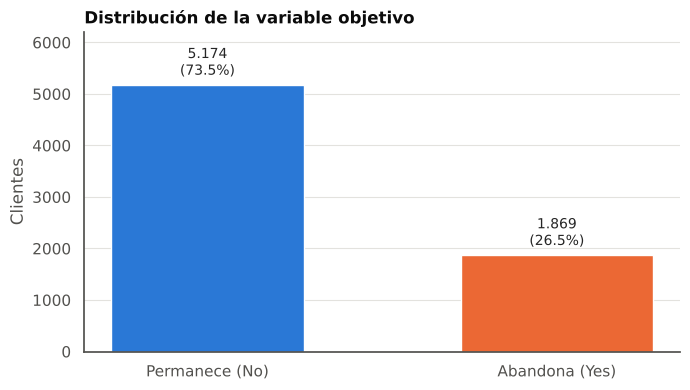

Relación No:Yes = 2.77 : 1
Un modelo que siempre responde «No» tendría exactitud de 73.5% y Recall de 0 %.


In [ ]:
conteo = df_eda["Churn"].value_counts().reindex(["No", "Yes"])
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(["Permanece (No)", "Abandona (Yes)"], conteo.values,
                color=[C["no"], C["churn"]], width=0.55)
ax.bar_label(barras, labels=[f"{v:,}".replace(",", ".") + f"\n({v / conteo.sum():.1%})" for v in conteo.values],
             padding=4, fontsize=10)
ax.set_ylim(0, conteo.max() * 1.2)
ax.set_ylabel("Clientes")
ax.set_title("Distribución de la variable objetivo")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

razon = conteo["No"] / conteo["Yes"]
print(f"Relación No:Yes = {razon:.2f} : 1")
print(f"Un modelo que siempre responde «No» tendría exactitud de {conteo['No'] / conteo.sum():.1%} y Recall de 0 %.")

## 2.5 Variables numéricas: antigüedad y facturación

Se comparan las tres variables numéricas entre quienes se van y quienes se quedan. Arriba, la forma de la distribución (densidad, para que el desbalance no distorsione la comparación); abajo, un diagrama de cajas con la mediana y los valores extremos.

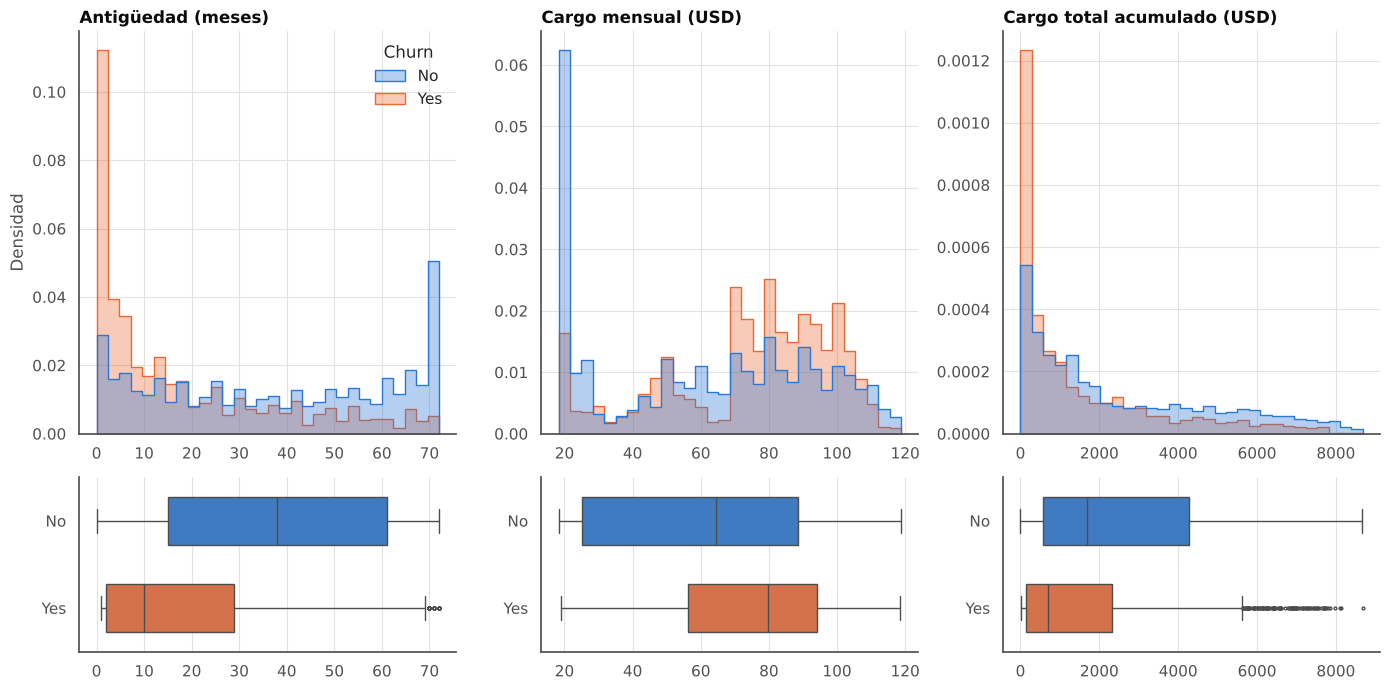

tenure       MonthlyCharges       TotalCharges        
      median  mean         median  mean       median    mean
Churn                                                       
No      38.0  37.6           64.4  61.3       1679.5  2549.9
Yes     10.0  18.0           79.6  74.4        703.6  1531.8

In [ ]:
variables_num = ["tenure", "MonthlyCharges", "TotalCharges"]
etiquetas_num = {"tenure": "Antigüedad (meses)", "MonthlyCharges": "Cargo mensual (USD)",
                 "TotalCharges": "Cargo total acumulado (USD)"}
paleta = {"No": C["no"], "Yes": C["churn"]}

fig, ejes = plt.subplots(2, 3, figsize=(14, 7), gridspec_kw={"height_ratios": [3, 1.3]})
for j, v in enumerate(variables_num):
    ax = ejes[0, j]
    sns.histplot(data=df_eda, x=v, hue="Churn", hue_order=["No", "Yes"], palette=paleta,
                 stat="density", common_norm=False, element="step", alpha=0.35, bins=30,
                 ax=ax, legend=(j == 0))
    ax.set_title(etiquetas_num[v])
    ax.set_xlabel("")
    ax.set_ylabel("Densidad" if j == 0 else "")
    ax2 = ejes[1, j]
    sns.boxplot(data=df_eda, x=v, y="Churn", hue="Churn", order=["No", "Yes"], hue_order=["No", "Yes"],
                palette=paleta, width=0.55, fliersize=2, linewidth=1, ax=ax2, legend=False)
    ax2.set_xlabel("")
    ax2.set_ylabel("")
    ax2.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

resumen_num = df_eda.groupby("Churn")[variables_num].agg(["median", "mean"]).round(1)
display(resumen_num)

## 2.6 Variables categóricas: ¿en qué grupos se concentra el abandono?

Cada panel muestra la **tasa de abandono por categoría** de una variable. La línea punteada es la tasa global; las barras **naranjas** superan el promedio por más de 2 puntos, las **azules** quedan más de 2 puntos bajo él y las **grises** son similares al promedio. Es la forma más rápida de ver qué perfiles de cliente concentran el riesgo.

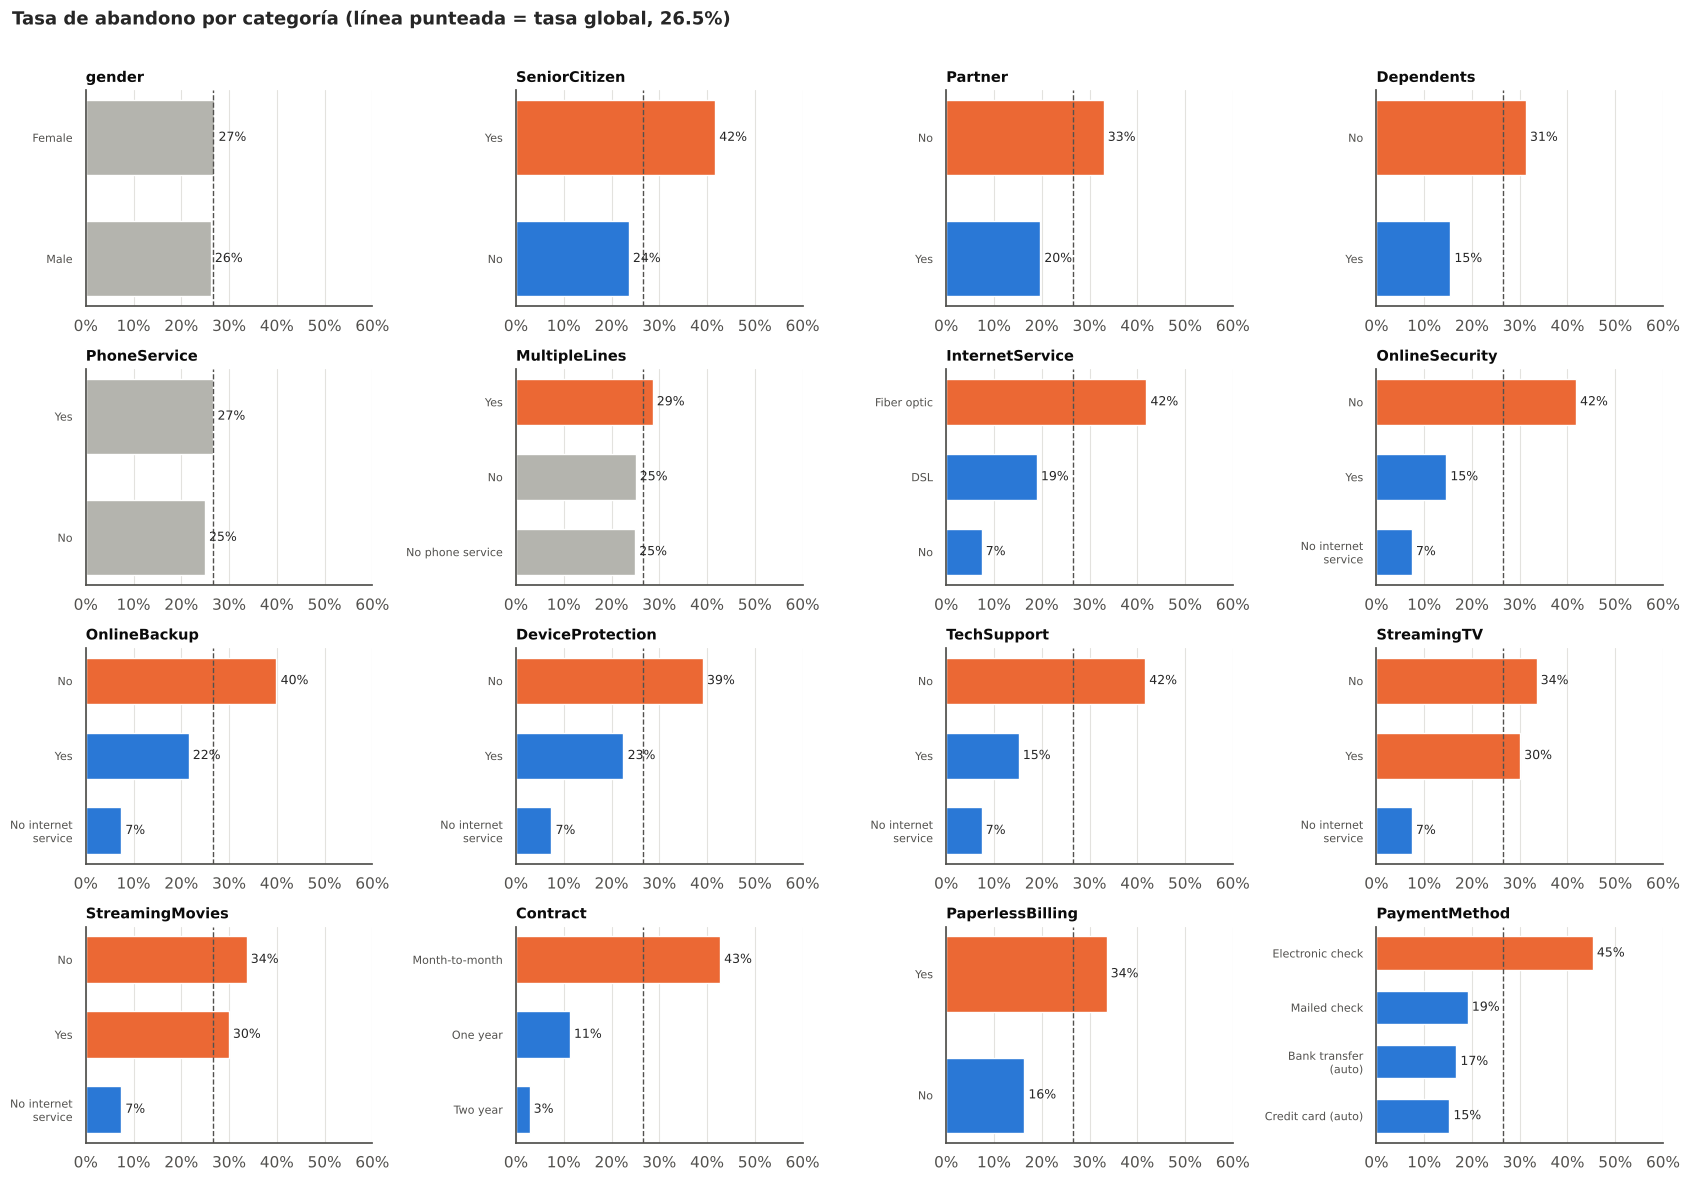

In [ ]:
cat_vars = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
            "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

fig, ejes = plt.subplots(4, 4, figsize=(17, 12))
for ax, v in zip(ejes.ravel(), cat_vars):
    tasas = df_eda.groupby(v)["churn"].mean().sort_values()
    colores = [C["churn"] if t > TASA_GLOBAL + 0.02 else (C["no"] if t < TASA_GLOBAL - 0.02 else "#b4b4ae") for t in tasas]
    etiquetas = [textwrap.fill(str(i).replace(" (automatic)", " (auto)"), 18) for i in tasas.index]
    barras = ax.barh(etiquetas, tasas.values, color=colores, height=0.62)
    ax.bar_label(barras, labels=[f"{t:.0%}" for t in tasas.values], padding=3, fontsize=9)
    ax.axvline(TASA_GLOBAL, color=C["tinta2"], linestyle="--", linewidth=1)
    ax.set_xlim(0, 0.6)
    ax.set_title(v, fontsize=10.5)
    ax.tick_params(axis="y", labelsize=8)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Tasa de abandono por categoría (línea punteada = tasa global, {TASA_GLOBAL:.1%})",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

### Intensidad de la asociación con el abandono

La tasa por categoría muestra *dónde* hay riesgo, pero no *cuánto pesa* cada variable. Para compararlas en una sola escala se usa la **V de Cramér** (0 = sin asociación, 1 = asociación perfecta) entre cada variable categórica y `Churn`. Se destacan en naranja las tres con mayor asociación.

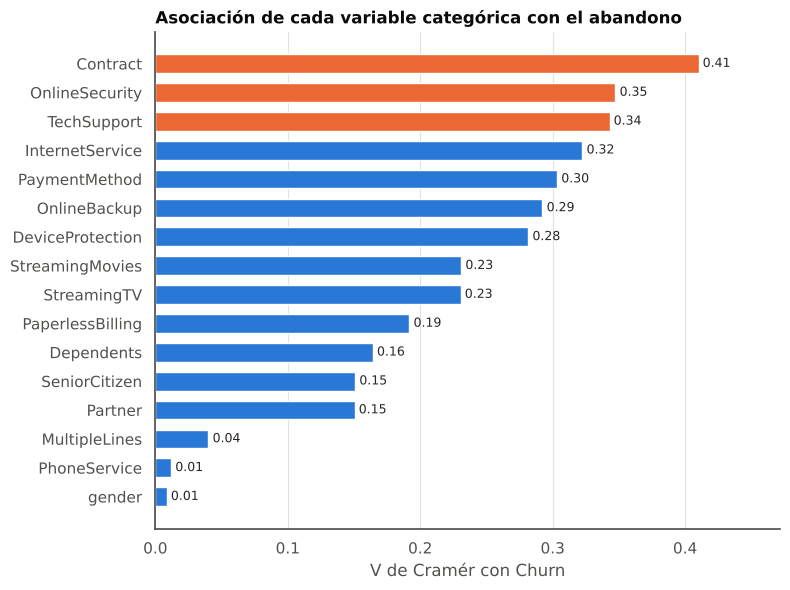

In [ ]:
def cramer_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    return float(np.sqrt(chi2 / (n * (min(tabla.shape) - 1))))

asociacion = pd.Series({v: cramer_v(df_eda[v], df_eda["Churn"]) for v in cat_vars}).sort_values()
colores = [C["churn"] if i >= len(asociacion) - 3 else C["no"] for i in range(len(asociacion))]

fig, ax = plt.subplots(figsize=(8, 6))
barras = ax.barh(asociacion.index, asociacion.values, color=colores, height=0.65)
ax.bar_label(barras, labels=[f"{v:.2f}" for v in asociacion.values], padding=3, fontsize=9)
ax.set_xlim(0, asociacion.max() * 1.15)
ax.set_xlabel("V de Cramér con Churn")
ax.set_title("Asociación de cada variable categórica con el abandono")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 2.7 Interacciones: contrato, antigüedad e internet

La hipótesis H1 del informe sostiene que el abandono depende de **interacciones** entre `Contract`, `tenure` y el tipo de servicio. Los mapas de calor muestran la tasa de abandono al cruzar dos variables a la vez; cada celda incluye el tamaño de la muestra (*n*) para no sobreinterpretar combinaciones con pocos clientes.

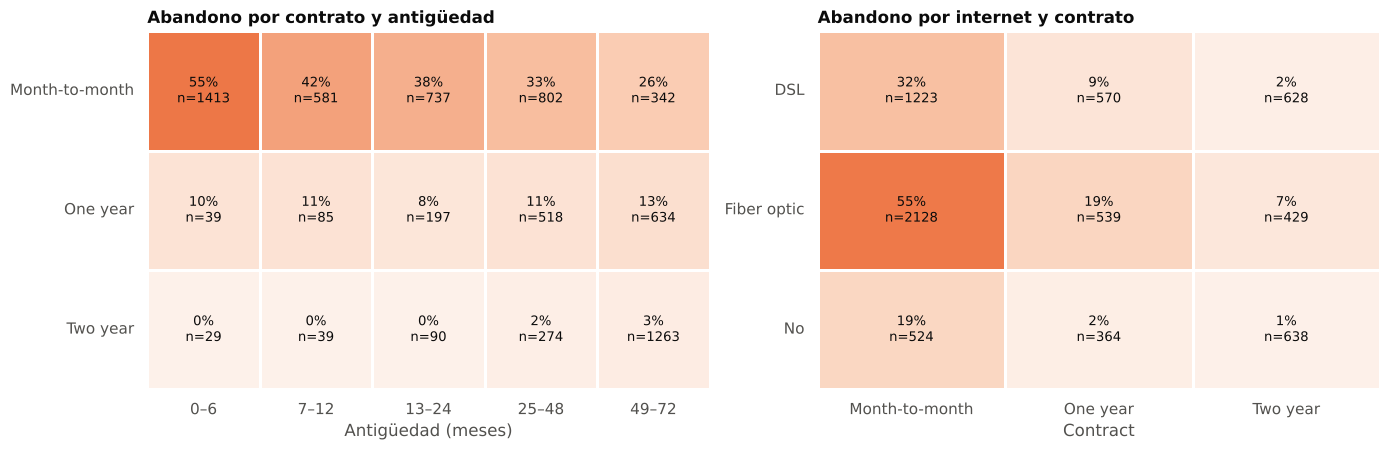

In [ ]:
df_eda["tramo_tenure"] = pd.cut(df_eda["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                                labels=["0–6", "7–12", "13–24", "25–48", "49–72"])

def mapa_calor(ax, datos, fila, columna, titulo, orden_filas=None, etiqueta_x=None):
    tasas = datos.pivot_table(index=fila, columns=columna, values="churn", aggfunc="mean", observed=True)
    tamanos = datos.pivot_table(index=fila, columns=columna, values="churn", aggfunc="size", observed=True)
    if orden_filas is not None:
        tasas = tasas.reindex(orden_filas)
        tamanos = tamanos.reindex(orden_filas)
    texto = tasas.copy().astype(object)
    for f in tasas.index:
        for c in tasas.columns:
            valor = tasas.loc[f, c]
            texto.loc[f, c] = "—" if pd.isna(valor) else f"{valor:.0%}\nn={int(tamanos.loc[f, c])}"
    sns.heatmap(tasas, annot=texto, fmt="", cmap=CMAP_SEC, vmin=0, vmax=0.6, linewidths=2,
                linecolor="white", cbar=False, ax=ax, annot_kws={"fontsize": 9.5, "color": C["tinta"]})
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x or str(columna))
    ax.set_ylabel("")
    ax.tick_params(axis="y", rotation=0)

orden_contrato = ["Month-to-month", "One year", "Two year"]
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.6))
mapa_calor(ejes[0], df_eda, "Contract", "tramo_tenure", "Abandono por contrato y antigüedad", orden_contrato, "Antigüedad (meses)")
mapa_calor(ejes[1], df_eda, "InternetService", "Contract", "Abandono por internet y contrato")
plt.tight_layout()
plt.show()

## 2.8 Hallazgos clave del análisis exploratorio

Las cifras de esta sección se **calculan a partir de los datos**, no están escritas a mano, de modo que siempre coinciden con los gráficos anteriores.

In [ ]:
def tasa(mascara):
    return df_eda.loc[mascara, "churn"].mean()

mtm, uno, dos = (tasa(df_eda["Contract"] == k) for k in orden_contrato)
fibra, dsl, sin_int = (tasa(df_eda["InternetService"] == k) for k in ["Fiber optic", "DSL", "No"])
cheque, otros_pagos = tasa(df_eda["PaymentMethod"] == "Electronic check"), tasa(df_eda["PaymentMethod"] != "Electronic check")
sin_soporte, con_soporte = tasa(df_eda["TechSupport"] == "No"), tasa(df_eda["TechSupport"] == "Yes")
mayor, no_mayor = tasa(df_eda["SeniorCitizen"] == "Yes"), tasa(df_eda["SeniorCitizen"] == "No")
nuevos, antiguos = tasa(df_eda["tenure"] <= 12), tasa(df_eda["tenure"] > 48)
dif_genero = abs(tasa(df_eda["gender"] == "Female") - tasa(df_eda["gender"] == "Male"))
med_ten = df_eda.groupby("Churn")["tenure"].median()
med_cargo = df_eda.groupby("Churn")["MonthlyCharges"].median()
top3 = ", ".join(f"`{v}`" for v in asociacion.sort_values(ascending=False).index[:3])

lineas = [
    f"- **Contrato:** la tasa de abandono es {mtm:.1%} con contrato mensual, {uno:.1%} a un año y {dos:.1%} a dos años. Es la señal más fuerte del dataset.",
    f"- **Antigüedad:** la mediana de permanencia es {med_ten['Yes']:.0f} meses entre quienes se van y {med_ten['No']:.0f} entre quienes se quedan. Hasta 12 meses el abandono es {nuevos:.1%}; sobre 48 meses, {antiguos:.1%}.",
    f"- **Internet:** la fibra óptica abandona al {fibra:.1%}, el DSL al {dsl:.1%} y quienes no tienen internet al {sin_int:.1%}.",
    f"- **Soporte técnico:** sin soporte el abandono es {sin_soporte:.1%}; con soporte, {con_soporte:.1%}.",
    f"- **Medio de pago:** el cheque electrónico concentra {cheque:.1%} de abandono frente a {otros_pagos:.1%} en los demás medios.",
    f"- **Facturación:** la mediana del cargo mensual es USD {med_cargo['Yes']:.1f} entre quienes se van y USD {med_cargo['No']:.1f} entre quienes se quedan.",
    f"- **Demografía:** los adultos mayores abandonan al {mayor:.1%} frente a {no_mayor:.1%}. La diferencia entre hombres y mujeres es de solo {dif_genero * 100:.1f} puntos.",
    f"- **Variables más asociadas (V de Cramér):** {top3}.",
]
display(Markdown("\n".join(lineas)))

- **Contrato:** la tasa de abandono es 42.7% con contrato mensual, 11.3% a un año y 2.8% a dos años. Es la señal más fuerte del dataset.
- **Antigüedad:** la mediana de permanencia es 10 meses entre quienes se van y 38 entre quienes se quedan. Hasta 12 meses el abandono es 47.4%; sobre 48 meses, 9.5%.
- **Internet:** la fibra óptica abandona al 41.9%, el DSL al 19.0% y quienes no tienen internet al 7.4%.
- **Soporte técnico:** sin soporte el abandono es 41.6%; con soporte, 15.2%.
- **Medio de pago:** el cheque electrónico concentra 45.3% de abandono frente a 17.1% en los demás medios.
- **Facturación:** la mediana del cargo mensual es USD 79.7 entre quienes se van y USD 64.4 entre quienes se quedan.
- **Demografía:** los adultos mayores abandonan al 41.7% frente a 23.6%. La diferencia entre hombres y mujeres es de solo 0.8 puntos.
- **Variables más asociadas (V de Cramér):** `Contract`, `OnlineSecurity`, `TechSupport`.

# Fase 3 · Preparación de los datos (Data Preparation)

Todas las transformaciones siguen el plan del informe y se organizan en dos grupos según si **aprenden** algo de los datos o no. Esa distinción es la que evita la **fuga de datos** (*data leakage*):

| Decisión | Justificación | Dónde se aplica |
|---|---|---|
| Convertir `TotalCharges` a número e imputar `0.0` cuando `tenure = 0` | Son clientes nuevos sin facturación acumulada | Función de limpieza (regla fija, no aprende) |
| Unificar «No internet service» y «No phone service» como «No» | Evita redundancia con `InternetService` y `PhoneService` | Función de limpieza (regla fija) |
| Variables binarias (`Yes`/`No`, `gender`) a `1`/`0` | Los modelos requieren números | Función de limpieza (regla fija) |
| Excluir `customerID` | Identificador único de alta cardinalidad: induciría sobreajuste | Función de limpieza |
| `Contract` como ordinal (mensual 0, un año 1, dos años 2) | Tiene un orden natural de compromiso | Pipeline (ajustado solo con entrenamiento) |
| *One-Hot Encoding* con `drop="first"` en `InternetService` y `PaymentMethod` | Son nominales sin orden | Pipeline (ajustado solo con entrenamiento) |
| `StandardScaler` en `tenure`, `MonthlyCharges`, `TotalCharges` | Reduce el efecto de la asimetría y la escala | Pipeline (ajustado solo con entrenamiento) |
| Conservar los valores atípicos | Son planes de mayor costo, filas válidas | — |

Las reglas fijas se aplican antes de dividir porque no usan información del conjunto de datos. Todo lo que **sí aprende** (medias, desviaciones, categorías) vive dentro del `Pipeline` y se ajusta únicamente con el conjunto de entrenamiento.

## 3.1 Limpieza y codificación (reglas fijas)

In [ ]:
SERVICIOS = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
             "TechSupport", "StreamingTV", "StreamingMovies"]
BINARIAS = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"] + SERVICIOS

def preparar_atributos(datos):
    X = datos.drop(columns=[c for c in ["customerID", "Churn"] if c in datos.columns]).copy()
    X["TotalCharges"] = pd.to_numeric(X["TotalCharges"], errors="coerce")
    X.loc[X["TotalCharges"].isna() & (X["tenure"] == 0), "TotalCharges"] = 0.0
    for c in SERVICIOS:
        X[c] = X[c].replace({"No internet service": "No", "No phone service": "No"})
    for c in BINARIAS:
        X[c] = X[c].map({"Yes": 1, "No": 0})
    X["gender"] = X["gender"].map({"Male": 1, "Female": 0})
    return X

def codificar_objetivo(datos):
    return (datos["Churn"] == "Yes").astype(int)

X = preparar_atributos(df_raw)
y = codificar_objetivo(df_raw)

print(f"Matriz de atributos: {X.shape[0]:,} filas × {X.shape[1]} columnas".replace(",", "."))
print(f"Valores nulos restantes: {int(X.isna().sum().sum())}")
print(f"Valores de MultipleLines tras unificar: {sorted(X['MultipleLines'].unique())}")
print(f"customerID presente en X: {'customerID' in X.columns}")
display(X.head())

Matriz de atributos: 7.043 filas × 19 columnas
Valores nulos restantes: 0
Valores de MultipleLines tras unificar: [np.int64(0), np.int64(1)]
customerID presente en X: False


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65


## 3.2 Partición estratificada entrenamiento / prueba

Se reserva el **20 % para prueba** con `stratify=y` y `random_state=42`, de modo que ambos conjuntos conserven la misma proporción de abandono (26,54 %). El conjunto de prueba **no se toca** hasta la Fase 5: todas las decisiones de modelado (hiperparámetros, umbral) se toman solo con el entrenamiento.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

particion = pd.DataFrame({
    "filas": [len(X_train), len(X_test), len(X)],
    "abandonos (Churn = 1)": [int(y_train.sum()), int(y_test.sum()), int(y.sum())],
    "tasa de abandono": [y_train.mean(), y_test.mean(), y.mean()],
}, index=["Entrenamiento", "Prueba", "Total"])
particion["tasa de abandono"] = particion["tasa de abandono"].map("{:.2%}".format)
display(particion)

print(f"Informe: 5.634 entrenamiento / 1.409 prueba → observado: {len(X_train):,} / {len(X_test):,}".replace(",", "."))

,filas,abandonos (Churn = 1),tasa de abandono
Entrenamiento,5634,1495,26.54%
Prueba,1409,374,26.54%
Total,7043,1869,26.54%


Informe: 5.634 entrenamiento / 1.409 prueba → observado: 5.634 / 1.409


## 3.3 Pipeline de preprocesamiento (aprende solo con entrenamiento)

El `ColumnTransformer` aplica a cada grupo de columnas su transformación. Las columnas binarias ya vienen en `0/1` y pasan sin cambios (`remainder="passthrough"`). La misma función construye un preprocesador nuevo para cada modelo, de manera que **cada ajuste parte de cero** y nunca reutiliza estadísticas de otro conjunto.

In [ ]:
NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges"]
NOMINALES = ["InternetService", "PaymentMethod"]
ORDEN_CONTRATO = [["Month-to-month", "One year", "Two year"]]

def construir_preprocesador():
    transformador = ColumnTransformer(
        transformers=[
            ("numericas", StandardScaler(), NUMERICAS),
            ("contrato", OrdinalEncoder(categories=ORDEN_CONTRATO), ["Contract"]),
            ("nominales", OneHotEncoder(drop="first", sparse_output=False), NOMINALES),
        ],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    return transformador.set_output(transform="pandas")

preprocesador = construir_preprocesador()
display(preprocesador)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('contrato', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for featur

In [ ]:
Xtr_t = preprocesador.fit_transform(X_train)
Xte_t = preprocesador.transform(X_test)

print(f"Entrenamiento transformado: {Xtr_t.shape[0]:,} × {Xtr_t.shape[1]} columnas".replace(",", "."))
print(f"Columnas resultantes: {list(Xtr_t.columns)}\n")

comprobacion = pd.DataFrame({
    "media (entrenamiento)": Xtr_t[NUMERICAS].mean(),
    "desv. (entrenamiento)": Xtr_t[NUMERICAS].std(ddof=0),
    "media (prueba)": Xte_t[NUMERICAS].mean(),
    "desv. (prueba)": Xte_t[NUMERICAS].std(ddof=0),
}).round(3)
display(comprobacion)

Entrenamiento transformado: 5.634 × 22 columnas
Columnas resultantes: ['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']



,media (entrenamiento),desv. (entrenamiento),media (prueba),desv. (prueba)
tenure,-0.0,1.0,-0.023,0.998
MonthlyCharges,-0.0,1.0,-0.028,0.992
TotalCharges,0.0,1.0,-0.043,0.972


**Cómo leer la tabla:** en entrenamiento las variables escaladas quedan con media 0 y desviación 1 por construcción. En prueba **no** son exactamente 0 y 1, y eso es lo correcto: el escalador se ajustó únicamente con entrenamiento y luego se aplicó a prueba sin volver a aprender nada. Si ambos conjuntos aparecieran perfectamente centrados, habría indicios de fuga de datos.

# Fase 4 · Modelado (Modeling)

## 4.1 Plan de modelado

| Modelo | Configuración base | Por qué |
|---|---|---|
| **Baseline** | `DummyClassifier(strategy="stratified")` (contrastado con `most_frequent`) | Piso mínimo de referencia: lo que se logra sin aprender patrones |
| **Modelo 1** | `LogisticRegression(class_weight="balanced")` | Lineal, interpretable mediante coeficientes y *odds ratios* |
| **Modelo 2** | `RandomForestClassifier(class_weight="balanced")` | Ensamble de árboles; captura interacciones no lineales (Breiman, 2001) |
| **Modelo 3** | `HistGradientBoostingClassifier` | Ensamble secuencial que corrige errores residuales; suele rendir bien en datos tabulares mixtos |

**Protocolo:** validación cruzada `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` **solo sobre el conjunto de entrenamiento**. Cada modelo se encapsula en un `Pipeline` junto con el preprocesador, así que en cada pliegue el escalado y la codificación se reajustan con los datos de ese pliegue.

## 4.2 Validación cruzada de los modelos base

Primero se evalúa cada modelo con hiperparámetros por defecto. El objetivo es medir la **estabilidad** (promedio ± desviación entre pliegues) antes de optimizar nada.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def pipeline_con(modelo):
    return Pipeline([("prep", construir_preprocesador()), ("modelo", modelo)])

METRICAS_CV = {
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

MODELOS_BASE = {
    "Baseline (Dummy)": DummyClassifier(strategy="stratified", random_state=SEED),
    "Baseline (most_frequent)": DummyClassifier(strategy="most_frequent"),
    "Regresión Logística": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=300, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEED),
}

resultados_cv = {}
for nombre, modelo in MODELOS_BASE.items():
    resultados_cv[nombre] = cross_validate(pipeline_con(modelo), X_train, y_train, cv=cv,
                                           scoring=METRICAS_CV, n_jobs=-1)

tabla_cv = pd.DataFrame({
    nombre: {m: f"{r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}" for m in METRICAS_CV}
    for nombre, r in resultados_cv.items()
}).T
tabla_cv.columns = ["Recall", "Precisión", "F1", "ROC-AUC", "PR-AUC"]
display(tabla_cv)

,Recall,Precisión,F1,ROC-AUC,PR-AUC
Baseline (Dummy),0.278 ± 0.025,0.275 ± 0.025,0.276 ± 0.025,0.507 ± 0.017,0.269 ± 0.007
Baseline (most_frequent),0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.265 ± 0.000
Regresión Logística,0.803 ± 0.038,0.518 ± 0.018,0.629 ± 0.023,0.846 ± 0.012,0.660 ± 0.020
Random Forest,0.650 ± 0.034,0.577 ± 0.023,0.611 ± 0.025,0.829 ± 0.011,0.620 ± 0.032
Gradient Boosting,0.517 ± 0.023,0.639 ± 0.021,0.571 ± 0.019,0.837 ± 0.009,0.644 ± 0.024


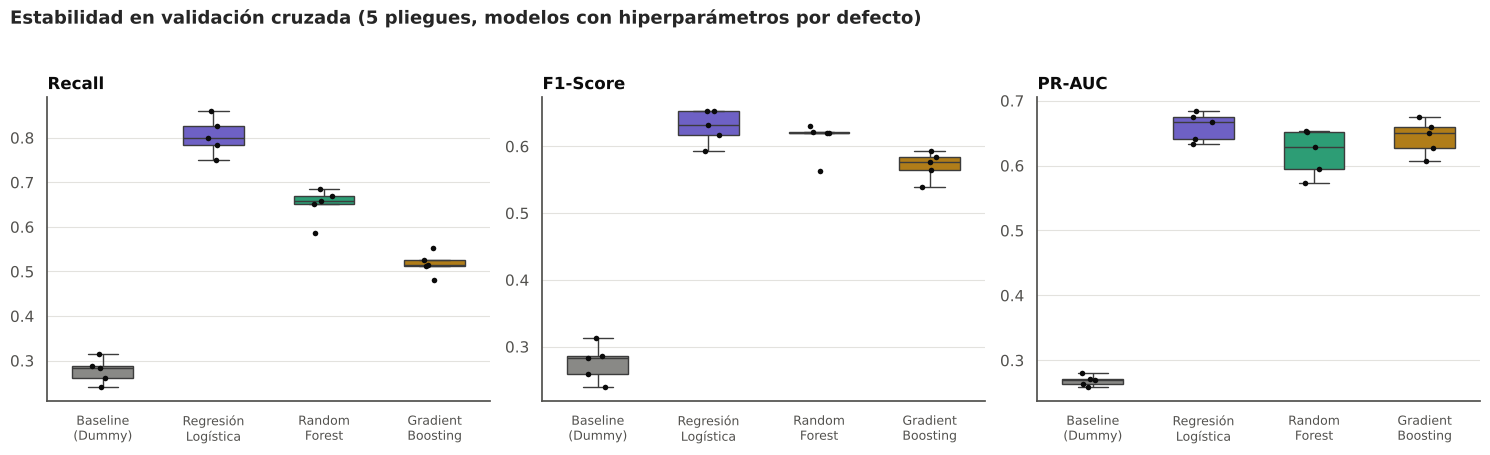

In [ ]:
ORDEN_CV = ["Baseline (Dummy)", "Regresión Logística", "Random Forest", "Gradient Boosting"]
largo = pd.DataFrame([
    {"modelo": n, "métrica": etiqueta, "valor": v}
    for n in ORDEN_CV
    for m, etiqueta in [("recall", "Recall"), ("f1", "F1-Score"), ("pr_auc", "PR-AUC")]
    for v in resultados_cv[n]["test_" + m]
])

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=False)
for ax, etiqueta in zip(ejes, ["Recall", "F1-Score", "PR-AUC"]):
    sub = largo[largo["métrica"] == etiqueta]
    sns.boxplot(data=sub, x="modelo", y="valor", hue="modelo", order=ORDEN_CV, hue_order=ORDEN_CV,
                palette=COLOR_MODELO, width=0.55, linewidth=1, fliersize=0, ax=ax, legend=False)
    sns.stripplot(data=sub, x="modelo", y="valor", order=ORDEN_CV, color=C["tinta"], size=4, ax=ax)
    ax.set_title(etiqueta)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks(range(len(ORDEN_CV)))
    ax.set_xticklabels([textwrap.fill(n, 12) for n in ORDEN_CV], fontsize=9)
    ax.grid(axis="x", visible=False)
fig.suptitle("Estabilidad en validación cruzada (5 pliegues, modelos con hiperparámetros por defecto)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 4.3 Ajuste de hiperparámetros

El informe prevé usar la validación cruzada también para **optimizar hiperparámetros**. Se busca con `average_precision` (PR-AUC) como criterio porque no depende de un umbral de decisión concreto: primero se elige el mejor *ranking* de riesgo y, en el paso siguiente, se fija el umbral que cumple el Recall objetivo.

- **Regresión Logística:** búsqueda exhaustiva sobre la fuerza de regularización `C`.
- **Random Forest** y **Gradient Boosting:** búsqueda aleatoria (15 combinaciones) para mantener un tiempo de ejecución razonable en Colab.

In [ ]:
import time

busquedas = {
    "Regresión Logística": GridSearchCV(
        pipeline_con(LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
        {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
        scoring="average_precision", cv=cv, n_jobs=-1),
    "Random Forest": RandomizedSearchCV(
        pipeline_con(RandomForestClassifier(class_weight="balanced", random_state=SEED)),
        {"modelo__n_estimators": [200, 300, 500],
         "modelo__max_depth": [4, 6, 8, 10, None],
         "modelo__min_samples_leaf": [1, 3, 5, 10, 20],
         "modelo__max_features": ["sqrt", 0.3, 0.5]},
        n_iter=15, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": RandomizedSearchCV(
        pipeline_con(HistGradientBoostingClassifier(random_state=SEED)),
        {"modelo__learning_rate": [0.02, 0.05, 0.1],
         "modelo__max_iter": [100, 200, 300],
         "modelo__max_depth": [2, 3, 4, None],
         "modelo__min_samples_leaf": [20, 40, 80],
         "modelo__l2_regularization": [0, 0.1, 1, 10]},
        n_iter=15, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=-1),
}

MODELOS = {}
filas = []
for nombre, busqueda in busquedas.items():
    inicio = time.time()
    busqueda.fit(X_train, y_train)
    MODELOS[nombre] = busqueda.best_estimator_
    por_defecto = resultados_cv[nombre]["test_pr_auc"].mean()
    filas.append({"modelo": nombre,
                  "PR-AUC (defecto)": round(por_defecto, 4),
                  "PR-AUC (ajustado)": round(busqueda.best_score_, 4),
                  "mejores hiperparámetros": {k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()},
                  "segundos": round(time.time() - inicio, 1)})
display(pd.DataFrame(filas).set_index("modelo"))

,PR-AUC (defecto),PR-AUC (ajustado),mejores hiperparámetros,segundos
modelo,,,,
Regresión Logística,0.6600,0.6600,{'C': 1},0.5
Random Forest,0.6203,0.6643,"{'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 10}",37.5
Gradient Boosting,0.6438,0.6662,"{'min_samples_leaf': 20, 'max_iter': 100, 'max_depth': 4, 'learning_rate': 0.1, 'l2_regularization': 10}",6.1


## 4.4 Elección del umbral de decisión

Un clasificador entrega una **probabilidad**; el umbral decide a partir de qué valor se emite una alerta. Con el umbral por defecto (0,50) el modelo puede quedar corto de *Recall*, que es justamente lo que más importa. La regla aplicada a cada modelo es:

> Elegir el umbral que **maximiza el F1** entre los que logran un Recall de al menos `RECALL_OBJETIVO + MARGEN` en predicciones *fuera de muestra* del entrenamiento.

El margen de 0,02 evita elegir un umbral que cumple el objetivo «por un pelo» en validación y lo incumple en prueba por simple variación muestral. Las probabilidades se obtienen con `cross_val_predict` (cada cliente se puntúa con un modelo que **no lo vio**), por lo que el conjunto de prueba sigue intacto.

In [ ]:
def elegir_umbral(y_real, prob, recall_min):
    precision, recall, umbrales = precision_recall_curve(y_real, prob)
    precision, recall = precision[:-1], recall[:-1]
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    factibles = recall >= recall_min
    puntaje = np.where(factibles, f1, -1.0) if factibles.any() else f1
    i = int(np.argmax(puntaje))
    return float(umbrales[i]), bool(factibles.any())

PROB_OOF = {}
UMBRALES = {}
filas = []
for nombre, modelo in MODELOS.items():
    PROB_OOF[nombre] = cross_val_predict(clone(modelo), X_train, y_train, cv=cv,
                                         method="predict_proba", n_jobs=-1)[:, 1]
    UMBRALES[nombre], factible = elegir_umbral(y_train, PROB_OOF[nombre], RECALL_OBJETIVO + MARGEN_RECALL_UMBRAL)
    pred = PROB_OOF[nombre] >= UMBRALES[nombre]
    filas.append({"modelo": nombre, "umbral elegido": round(UMBRALES[nombre], 3),
                  "Recall (validación)": round(recall_score(y_train, pred), 3),
                  "Precisión (validación)": round(precision_score(y_train, pred), 3),
                  "F1 (validación)": round(f1_score(y_train, pred), 3),
                  "objetivo alcanzable": "sí" if factible else "no"})
display(pd.DataFrame(filas).set_index("modelo"))

,umbral elegido,Recall (validación),Precisión (validación),F1 (validación),objetivo alcanzable
modelo,,,,,
Regresión Logística,0.504,0.802,0.521,0.631,sí
Random Forest,0.484,0.800,0.522,0.632,sí
Gradient Boosting,0.264,0.803,0.524,0.634,sí


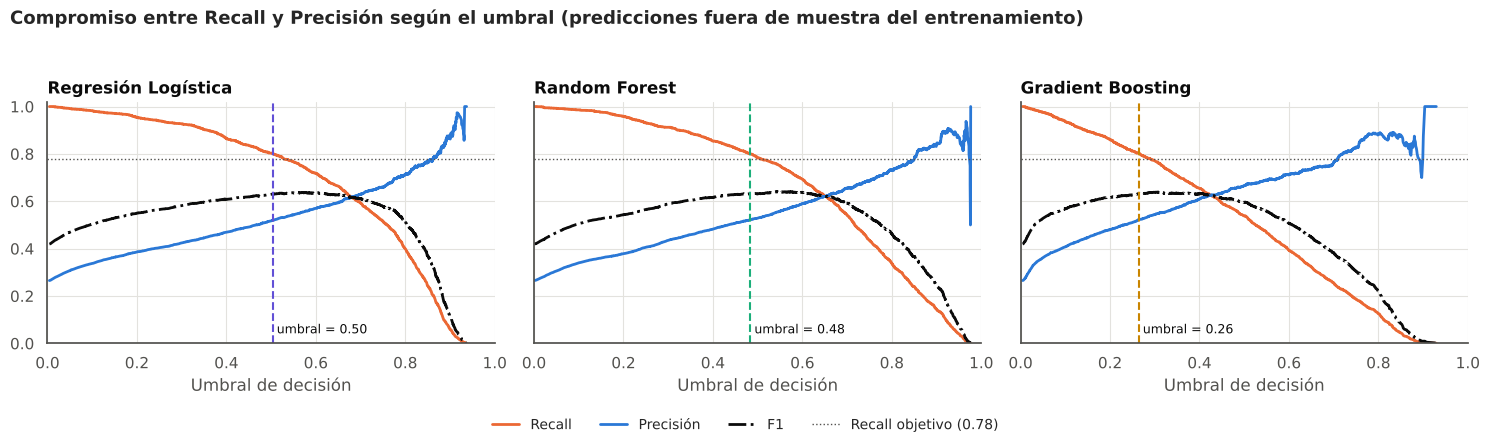

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, nombre in zip(ejes, MODELOS):
    prec, rec, umb = precision_recall_curve(y_train, PROB_OOF[nombre])
    prec, rec = prec[:-1], rec[:-1]
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    ax.plot(umb, rec, color=C["churn"], linewidth=2, label="Recall")
    ax.plot(umb, prec, color=C["no"], linewidth=2, label="Precisión")
    ax.plot(umb, f1, color=C["tinta"], linewidth=2, linestyle="-.", label="F1")
    ax.axhline(RECALL_OBJETIVO, color=C["tinta2"], linestyle=":", linewidth=1, label=f"Recall objetivo ({RECALL_OBJETIVO:.2f})")
    ax.axvline(UMBRALES[nombre], color=COLOR_MODELO[nombre], linestyle="--", linewidth=1.5)
    ax.text(UMBRALES[nombre], 0.03, f" umbral = {UMBRALES[nombre]:.2f}", color=C["tinta"], fontsize=9, va="bottom")
    ax.set_title(nombre)
    ax.set_xlabel("Umbral de decisión")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
manijas, rotulos = ejes[0].get_legend_handles_labels()
fig.legend(manijas, rotulos, loc="lower center", ncol=4, fontsize=10, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Compromiso entre Recall y Precisión según el umbral (predicciones fuera de muestra del entrenamiento)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0.07, 1, 0.93))
plt.show()

# Fase 5 · Evaluación (Evaluation)

Recién ahora se usa el **conjunto de prueba** (1.409 clientes que ningún modelo vio durante el ajuste). Cada modelo se evalúa dos veces: con el umbral convencional de 0,50 y con el umbral ajustado en la Fase 4. También se mide el desempeño sobre el propio entrenamiento para calcular la **brecha** (indicador de sobreajuste).

## 5.1 Métricas en prueba

In [ ]:
def metricas_clasif(y_real, prob, umbral):
    pred = (prob >= umbral).astype(int)
    return {"recall": recall_score(y_real, pred, zero_division=0),
            "precision": precision_score(y_real, pred, zero_division=0),
            "f1": f1_score(y_real, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_real, prob),
            "pr_auc": average_precision_score(y_real, prob)}

PROB_TEST = {n: m.predict_proba(X_test)[:, 1] for n, m in MODELOS.items()}
PROB_TRAIN = {n: m.predict_proba(X_train)[:, 1] for n, m in MODELOS.items()}

baseline = pipeline_con(DummyClassifier(strategy="stratified", random_state=SEED)).fit(X_train, y_train)
pred_base_te = baseline.predict(X_test)
pred_base_tr = baseline.predict(X_train)
prob_base_te = baseline.predict_proba(X_test)[:, 1]
metricas_base = {"recall": recall_score(y_test, pred_base_te), "precision": precision_score(y_test, pred_base_te),
                 "f1": f1_score(y_test, pred_base_te), "roc_auc": roc_auc_score(y_test, prob_base_te),
                 "pr_auc": average_precision_score(y_test, prob_base_te)}

filas = [{"modelo": "Baseline (Dummy)", "decisión": "estratificado", "umbral": np.nan, **metricas_base,
          "F1 train": f1_score(y_train, pred_base_tr),
          "brecha F1": f1_score(y_train, pred_base_tr) - metricas_base["f1"]}]
for nombre in MODELOS:
    for regla, umbral in (("umbral 0,50", 0.5), ("umbral ajustado", UMBRALES[nombre])):
        r_te = metricas_clasif(y_test, PROB_TEST[nombre], umbral)
        r_tr = metricas_clasif(y_train, PROB_TRAIN[nombre], umbral)
        filas.append({"modelo": nombre, "decisión": regla, "umbral": umbral, **r_te,
                      "F1 train": r_tr["f1"], "brecha F1": r_tr["f1"] - r_te["f1"]})
tabla_test = pd.DataFrame(filas)
display(tabla_test.round(3).set_index(["modelo", "decisión"]))

umbral  recall  precision     f1  roc_auc  pr_auc  F1 train  brecha F1
modelo              decisión                                                                               
Baseline (Dummy)    estratificado       NaN   0.291      0.289  0.290    0.516   0.272     0.278     -0.012
Regresión Logística umbral 0,50       0.500   0.786      0.507  0.616    0.842   0.634     0.634      0.018
                    umbral ajustado   0.504   0.781      0.507  0.615    0.842   0.634     0.635      0.020
Random Forest       umbral 0,50       0.500   0.805      0.531  0.640    0.847   0.651     0.676      0.036
                    umbral ajustado   0.484   0.810      0.522  0.635    0.847   0.651     0.674      0.040
Gradient Boosting   umbral 0,50       0.500   0.537      0.648  0.588    0.844   0.653     0.634      0.047
                    umbral ajustado   0.264   0.791      0.515  0.624    0.844   0.653     0.669      0.045

## 5.2 Matrices de confusión

Cada matriz muestra, con el umbral ajustado, cuántos clientes de cada tipo real cayeron en cada decisión. La fila inferior (**abandonan**) es la que importa para el negocio: el casillero inferior derecho son las fugas detectadas a tiempo y el inferior izquierdo son las fugas que se escaparon.

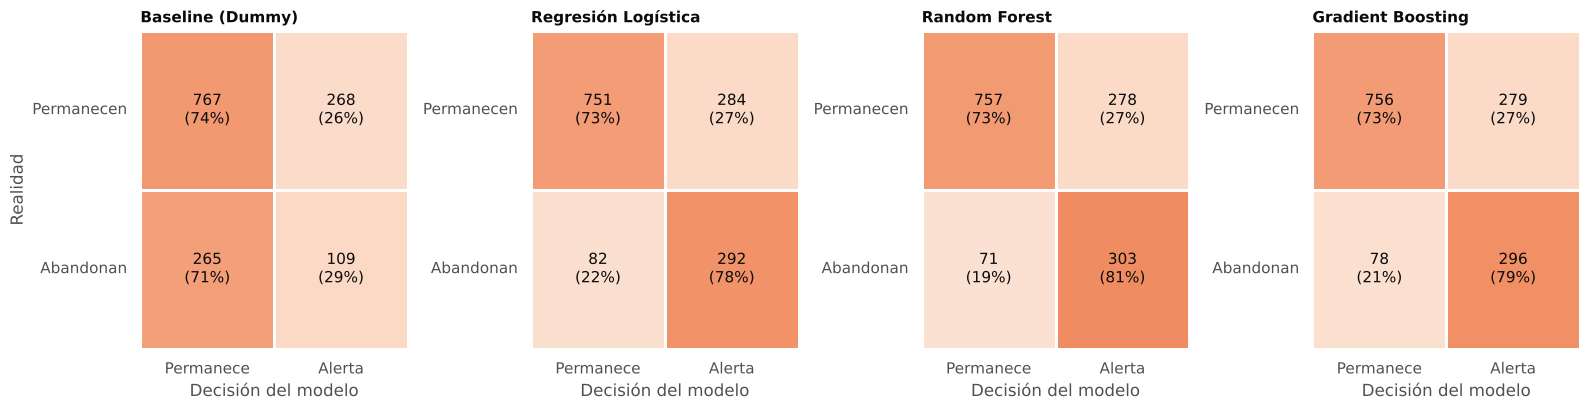

In [ ]:
def matriz(y_real, pred):
    m = np.zeros((2, 2), dtype=int)
    for a, p in zip(np.asarray(y_real), np.asarray(pred)):
        m[int(a), int(p)] += 1
    return m

paneles = [("Baseline (Dummy)", pred_base_te)] + [(n, (PROB_TEST[n] >= UMBRALES[n]).astype(int)) for n in MODELOS]
fig, ejes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (nombre, pred) in zip(ejes, paneles):
    m = matriz(y_test, pred)
    porcentajes = m / m.sum(axis=1, keepdims=True)
    texto = np.array([[f"{m[i, j]}\n({porcentajes[i, j]:.0%})" for j in range(2)] for i in range(2)])
    sns.heatmap(porcentajes, annot=texto, fmt="", cmap=CMAP_SEC, vmin=0, vmax=1, cbar=False,
                linewidths=2, linecolor="white", ax=ax, annot_kws={"fontsize": 11, "color": C["tinta"]})
    ax.set_xticklabels(["Permanece", "Alerta"])
    ax.set_yticklabels(["Permanecen", "Abandonan"], rotation=0)
    ax.set_title(nombre, fontsize=11)
    ax.set_xlabel("Decisión del modelo")
    ax.set_ylabel("Realidad" if ax is ejes[0] else "")
plt.tight_layout()
plt.show()

## 5.3 Curvas ROC y Precisión–Recall

La curva **ROC** mide la capacidad de ordenar a los clientes (qué tan arriba quedan los que se van); la curva **Precisión–Recall** es más exigente cuando hay desbalance. El punto marcado en cada curva es el **umbral ajustado**. En la curva Precisión–Recall se sombrea la **zona objetivo del negocio** (Recall ≥ 0,78 y Precisión ≥ 0,55): un modelo cumple ambos criterios solo si su curva entra en esa zona.

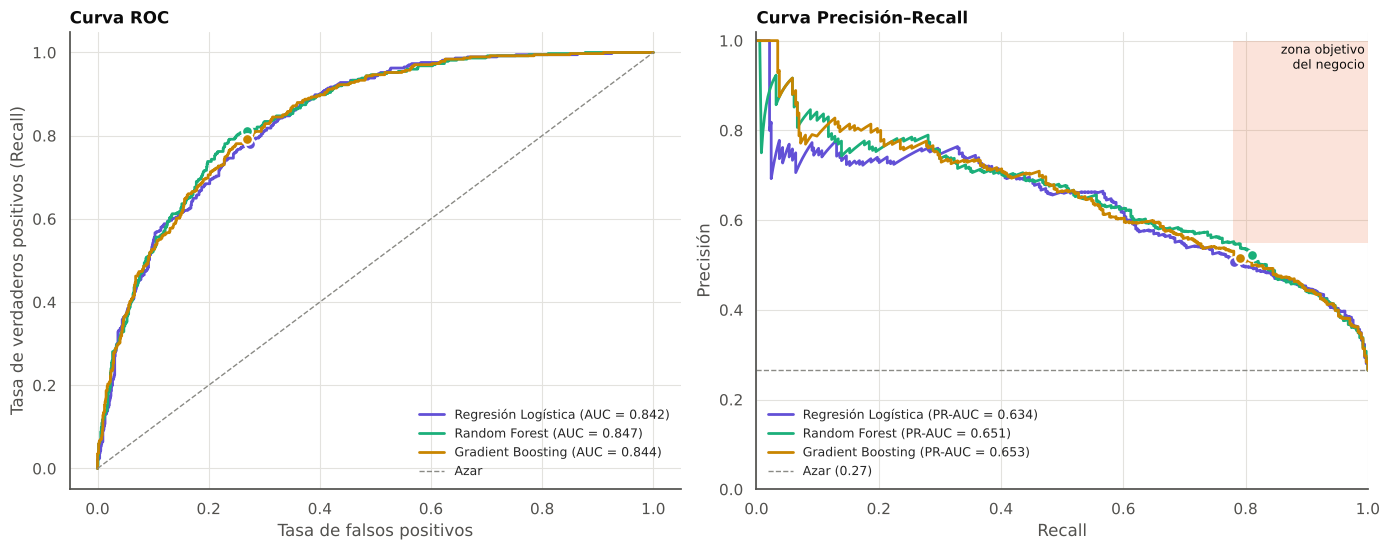

In [ ]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5.6))
for nombre in MODELOS:
    fpr, tpr, _ = roc_curve(y_test, PROB_TEST[nombre])
    prec, rec, _ = precision_recall_curve(y_test, PROB_TEST[nombre])
    auc = roc_auc_score(y_test, PROB_TEST[nombre])
    ap = average_precision_score(y_test, PROB_TEST[nombre])
    pred = PROB_TEST[nombre] >= UMBRALES[nombre]
    ax_roc.plot(fpr, tpr, color=COLOR_MODELO[nombre], linewidth=2, label=f"{nombre} (AUC = {auc:.3f})")
    ax_roc.scatter([((pred) & (y_test == 0)).sum() / (y_test == 0).sum()], [recall_score(y_test, pred)],
                   color=COLOR_MODELO[nombre], s=60, zorder=5, edgecolor="white", linewidth=1.5)
    ax_pr.plot(rec, prec, color=COLOR_MODELO[nombre], linewidth=2, label=f"{nombre} (PR-AUC = {ap:.3f})")
    ax_pr.scatter([recall_score(y_test, pred)], [precision_score(y_test, pred)],
                  color=COLOR_MODELO[nombre], s=60, zorder=5, edgecolor="white", linewidth=1.5)
ax_roc.plot([0, 1], [0, 1], color=C["base"], linestyle="--", linewidth=1, label="Azar")
ax_roc.set_xlabel("Tasa de falsos positivos")
ax_roc.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax_roc.set_title("Curva ROC")
ax_roc.legend(loc="lower right", fontsize=9)

ax_pr.axhline(y_test.mean(), color=C["base"], linestyle="--", linewidth=1, label=f"Azar ({y_test.mean():.2f})")
ax_pr.add_patch(plt.Rectangle((RECALL_OBJETIVO, PRECISION_NEGOCIO), 1 - RECALL_OBJETIVO, 1 - PRECISION_NEGOCIO,
                              color=C["churn"], alpha=0.18, linewidth=0))
ax_pr.text(0.995, 0.995, "zona objetivo\ndel negocio", ha="right", va="top", fontsize=9, color=C["tinta"])
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precisión")
ax_pr.set_title("Curva Precisión–Recall")
ax_pr.set_xlim(0, 1)
ax_pr.set_ylim(0, 1.02)
ax_pr.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

## 5.4 Selección del modelo ganador

La regla definida en el informe es: **ganador = el modelo que cumple Recall ≥ 0,78 en prueba y obtiene el mayor F1** (PR-AUC como desempate), verificando que la brecha entre entrenamiento y prueba no supere 5 puntos.

In [ ]:
ajustado = tabla_test[tabla_test["decisión"] == "umbral ajustado"].set_index("modelo")
cumplen = ajustado[(ajustado["recall"] >= RECALL_OBJETIVO) & (ajustado["brecha F1"] <= BRECHA_MAXIMA)]
REGLA_CUMPLIDA = not cumplen.empty
candidatos = cumplen if REGLA_CUMPLIDA else ajustado
GANADOR = candidatos.sort_values(["f1", "pr_auc"], ascending=False).index[0]
UMBRAL_FINAL = UMBRALES[GANADOR]
MODELO_FINAL = MODELOS[GANADOR]

comparacion = ajustado[["umbral", "recall", "precision", "f1", "pr_auc", "brecha F1"]].copy()
comparacion["Recall ≥ objetivo"] = np.where(comparacion["recall"] >= RECALL_OBJETIVO, "✅", "❌")
comparacion["brecha ≤ 5 pts"] = np.where(comparacion["brecha F1"] <= BRECHA_MAXIMA, "✅", "❌")
display(comparacion.round(3))

if REGLA_CUMPLIDA:
    texto = f"**Modelo ganador: {GANADOR}** (umbral {UMBRAL_FINAL:.2f}). Cumple Recall ≥ {RECALL_OBJETIVO} y brecha ≤ {BRECHA_MAXIMA * 100:.0f} pts, y es el de mayor F1 entre los que cumplen."
else:
    texto = (f"**Ningún modelo cumple a la vez Recall ≥ {RECALL_OBJETIVO} y brecha ≤ {BRECHA_MAXIMA * 100:.0f} pts en prueba.** "
             f"Se toma como referencia el de mayor F1: **{GANADOR}** (umbral {UMBRAL_FINAL:.2f}).")
display(Markdown(texto))

,umbral,recall,precision,f1,pr_auc,brecha F1,Recall ≥ objetivo,brecha ≤ 5 pts
modelo,,,,,,,,
Regresión Logística,0.504,0.781,0.507,0.615,0.634,0.020,✅,✅
Random Forest,0.484,0.810,0.522,0.635,0.651,0.040,✅,✅
Gradient Boosting,0.264,0.791,0.515,0.624,0.653,0.045,✅,✅


**Modelo ganador: Random Forest** (umbral 0.48). Cumple Recall ≥ 0.78 y brecha ≤ 5 pts, y es el de mayor F1 entre los que cumplen.

### ¿Cuánta confianza dar a la diferencia entre modelos?

El conjunto de prueba tiene 1.409 clientes y solo 374 abandonos, por lo que cualquier métrica tiene un margen de error. Para medirlo se usa **bootstrap**: se remuestrea 1.000 veces el conjunto de prueba (con reemplazo) y se recalculan las métricas de cada modelo con su umbral ajustado. Si los intervalos del 95 % de dos modelos se solapan mucho, **la diferencia observada puede ser azar**.

,Recall,Precisión,F1,P(Recall ≥ 0.78)
modelo,,,,
Regresión Logística,0.781 [0.737 – 0.820],0.507 [0.467 – 0.546],0.615 [0.577 – 0.649],52%
Random Forest,0.810 [0.769 – 0.849],0.522 [0.479 – 0.563],0.635 [0.598 – 0.669],93%
Gradient Boosting,0.791 [0.749 – 0.831],0.515 [0.473 – 0.556],0.624 [0.587 – 0.659],72%


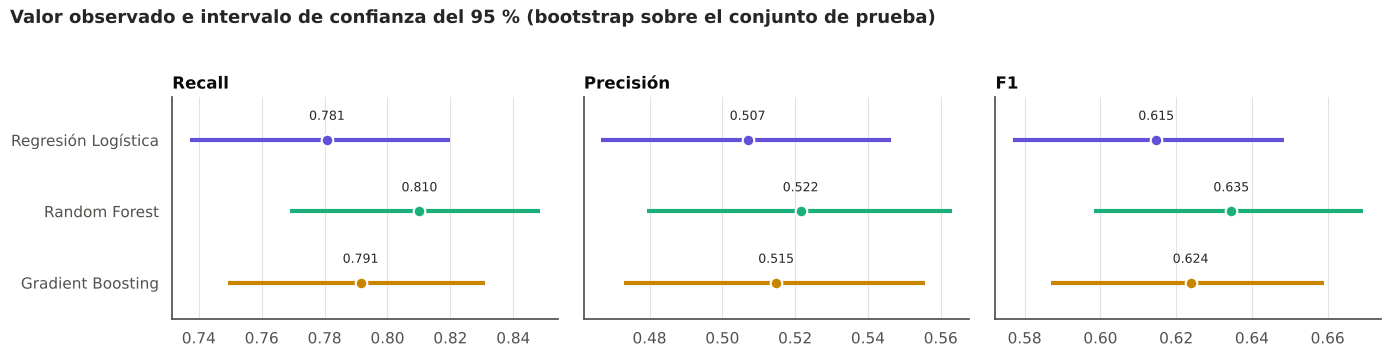

,diferencia observada,IC 95 %,P(diferencia > 0),distinguible del azar
comparación (F1),,,,
Random Forest − Regresión Logística,0.020,"[+0.001, +0.039]",98%,sí
Gradient Boosting − Regresión Logística,0.009,"[-0.009, +0.027]",82%,no


In [ ]:
rng = np.random.default_rng(SEED)
N_REMUESTREOS = 1000
y_arr = y_test.values
indices = rng.integers(0, len(y_arr), size=(N_REMUESTREOS, len(y_arr)))
pred_ajustada = {n: (PROB_TEST[n] >= UMBRALES[n]).astype(int) for n in MODELOS}

def metricas_remuestreadas(pred):
    yt, pr = y_arr[indices], pred[indices]
    tp = (yt * pr).sum(axis=1)
    fp = ((1 - yt) * pr).sum(axis=1)
    fn = (yt * (1 - pr)).sum(axis=1)
    recall = tp / np.clip(tp + fn, 1, None)
    precision = tp / np.clip(tp + fp, 1, None)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return {"Recall": recall, "Precisión": precision, "F1": f1}

remuestreos = {n: metricas_remuestreadas(pred_ajustada[n]) for n in MODELOS}
observado = {"Recall": "recall", "Precisión": "precision", "F1": "f1"}

filas = []
for n in MODELOS:
    fila = {"modelo": n}
    for m in ["Recall", "Precisión", "F1"]:
        bajo, alto = np.percentile(remuestreos[n][m], [2.5, 97.5])
        fila[m] = f"{ajustado.loc[n, observado[m]]:.3f} [{bajo:.3f} – {alto:.3f}]"
    fila[f"P(Recall ≥ {RECALL_OBJETIVO})"] = f"{(remuestreos[n]['Recall'] >= RECALL_OBJETIVO).mean():.0%}"
    filas.append(fila)
display(pd.DataFrame(filas).set_index("modelo"))

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, m in zip(ejes, ["Recall", "Precisión", "F1"]):
    for i, n in enumerate(MODELOS):
        bajo, alto = np.percentile(remuestreos[n][m], [2.5, 97.5])
        valor = ajustado.loc[n, observado[m]]
        ax.hlines(i, bajo, alto, color=COLOR_MODELO[n], linewidth=3)
        ax.scatter([valor], [i], color=COLOR_MODELO[n], s=70, zorder=5, edgecolor="white", linewidth=1.5)
        ax.text(valor, i - 0.28, f"{valor:.3f}", ha="center", fontsize=9)
    ax.set_yticks(range(len(MODELOS)))
    ax.set_yticklabels(list(MODELOS))
    ax.set_ylim(len(MODELOS) - 0.5, -0.6)
    ax.set_title(m)
    ax.grid(axis="y", visible=False)
fig.suptitle("Valor observado e intervalo de confianza del 95 % (bootstrap sobre el conjunto de prueba)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

filas = []
for n in ["Random Forest", "Gradient Boosting"]:
    dif = remuestreos[n]["F1"] - remuestreos["Regresión Logística"]["F1"]
    bajo, alto = np.percentile(dif, [2.5, 97.5])
    filas.append({"comparación (F1)": f"{n} − Regresión Logística", "diferencia observada": ajustado.loc[n, "f1"] - ajustado.loc["Regresión Logística", "f1"],
                  "IC 95 %": f"[{bajo:+.3f}, {alto:+.3f}]", "P(diferencia > 0)": f"{(dif > 0).mean():.0%}",
                  "distinguible del azar": "sí" if (bajo > 0 or alto < 0) else "no"})
tabla_dif = pd.DataFrame(filas).set_index("comparación (F1)")
display(tabla_dif.round(3))

## 5.5 Contraste de hipótesis

### H1 · Los ensambles superan a la Regresión Logística en al menos 0,05 de F1
Para comparar en igualdad de condiciones se usa la **misma regla de decisión (umbral 0,50)** en los tres modelos, de modo que la diferencia refleje la capacidad del algoritmo y no el umbral elegido para cada uno. Se muestra además la diferencia en PR-AUC, que no depende del umbral.

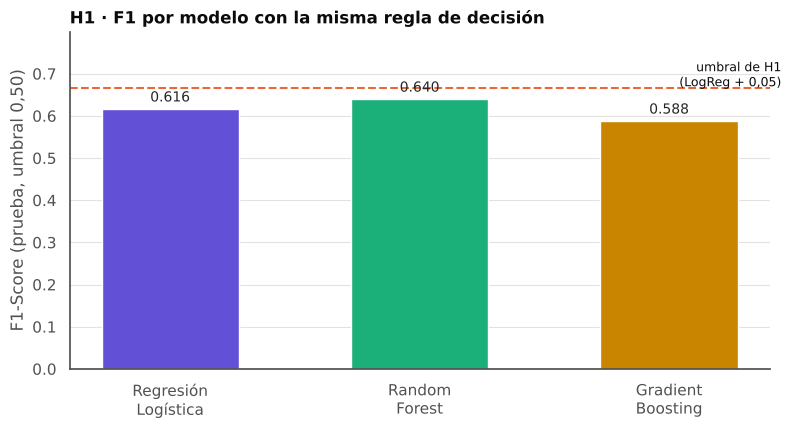

❌ **H1 se rechaza**: el mejor ensamble (Random Forest) obtiene una diferencia de F1 de **+0.023** respecto de la Regresión Logística (se exigía ≥ +0.05). En PR-AUC, que no depende del umbral, la diferencia es de +0.017.

In [ ]:
f1_05 = tabla_test[tabla_test["decisión"] == "umbral 0,50"].set_index("modelo")["f1"]
pr_auc_m = tabla_test[tabla_test["decisión"] == "umbral 0,50"].set_index("modelo")["pr_auc"]
mejor_ensamble = max(["Random Forest", "Gradient Boosting"], key=lambda n: f1_05[n])
dif_f1 = f1_05[mejor_ensamble] - f1_05["Regresión Logística"]
dif_pr = pr_auc_m[mejor_ensamble] - pr_auc_m["Regresión Logística"]
H1_CONFIRMADA = bool(dif_f1 >= MEJORA_H1_F1)

fig, ax = plt.subplots(figsize=(8, 4.4))
nombres = list(MODELOS)
barras = ax.bar([textwrap.fill(n, 12) for n in nombres], [f1_05[n] for n in nombres],
                color=[COLOR_MODELO[n] for n in nombres], width=0.55)
ax.bar_label(barras, labels=[f"{f1_05[n]:.3f}" for n in nombres], padding=3, fontsize=10)
ax.axhline(f1_05["Regresión Logística"] + MEJORA_H1_F1, color=C["churn"], linestyle="--", linewidth=1.5)
ax.text(2.45, f1_05["Regresión Logística"] + MEJORA_H1_F1 + 0.004, "umbral de H1\n(LogReg + 0,05)", ha="right",
        fontsize=9, color=C["tinta"])
ax.set_ylim(0, max(f1_05) * 1.25)
ax.set_ylabel("F1-Score (prueba, umbral 0,50)")
ax.set_title("H1 · F1 por modelo con la misma regla de decisión")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

veredicto = "✅ **H1 se confirma**" if H1_CONFIRMADA else "❌ **H1 se rechaza**"
display(Markdown(
    f"{veredicto}: el mejor ensamble ({mejor_ensamble}) obtiene una diferencia de F1 de **{dif_f1:+.3f}** respecto de la Regresión Logística "
    f"(se exigía ≥ {MEJORA_H1_F1:+.2f}). En PR-AUC, que no depende del umbral, la diferencia es de {dif_pr:+.3f}."))

### H2 · `class_weight="balanced"` + umbral 0,40 permite Recall ≥ 0,78 y +15 puntos
Se compara la Regresión Logística **sin ponderación** y con umbral 0,50 (el punto de partida «ingenuo») contra la **ponderada con umbral 0,40**. Se incluyen las dos combinaciones intermedias para separar el efecto de la ponderación del efecto del umbral.

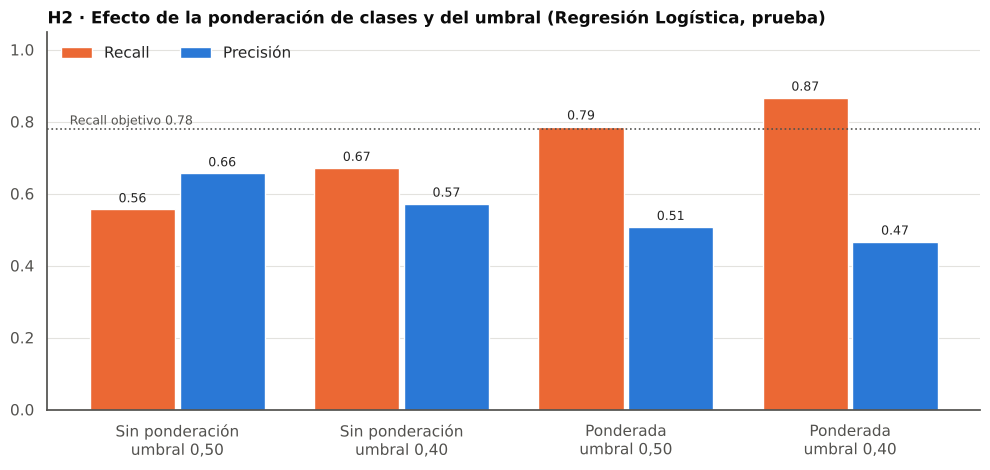

✅ **H2 se confirma**: el Recall pasa de **0.556** (sin ponderación, umbral 0,50) a **0.866** (ponderada, umbral 0,40), una mejora de **+31.0 puntos** (se exigía ≥ 15 puntos y Recall ≥ 0.78). El costo es la precisión: baja de 0.656 a 0.466.

In [ ]:
lr_sin_peso = clone(MODELOS["Regresión Logística"]).set_params(modelo__class_weight=None).fit(X_train, y_train)
prob_sin_peso = lr_sin_peso.predict_proba(X_test)[:, 1]
prob_con_peso = PROB_TEST["Regresión Logística"]

CLAVE_INICIAL = "Sin ponderación · umbral 0,50"
CLAVE_H2 = "Ponderada · umbral 0,40"
configuraciones = {
    CLAVE_INICIAL: metricas_clasif(y_test, prob_sin_peso, 0.50),
    "Sin ponderación · umbral 0,40": metricas_clasif(y_test, prob_sin_peso, UMBRAL_H2),
    "Ponderada · umbral 0,50": metricas_clasif(y_test, prob_con_peso, 0.50),
    CLAVE_H2: metricas_clasif(y_test, prob_con_peso, UMBRAL_H2),
}
recall_inicial = configuraciones[CLAVE_INICIAL]["recall"]
recall_h2 = configuraciones[CLAVE_H2]["recall"]
mejora_h2 = recall_h2 - recall_inicial
H2_CONFIRMADA = bool(recall_h2 >= RECALL_OBJETIVO and mejora_h2 >= MEJORA_H2_RECALL)

etiquetas = list(configuraciones)
posicion = np.arange(len(etiquetas))
fig, ax = plt.subplots(figsize=(10, 4.8))
b1 = ax.bar(posicion - 0.2, [configuraciones[e]["recall"] for e in etiquetas], 0.38, color=C["churn"], label="Recall")
b2 = ax.bar(posicion + 0.2, [configuraciones[e]["precision"] for e in etiquetas], 0.38, color=C["no"], label="Precisión")
ax.bar_label(b1, labels=[f"{configuraciones[e]['recall']:.2f}" for e in etiquetas], padding=3, fontsize=9)
ax.bar_label(b2, labels=[f"{configuraciones[e]['precision']:.2f}" for e in etiquetas], padding=3, fontsize=9)
ax.axhline(RECALL_OBJETIVO, color=C["tinta2"], linestyle=":", linewidth=1.2)
ax.text(-0.48, RECALL_OBJETIVO + 0.012, f"Recall objetivo {RECALL_OBJETIVO:.2f}", ha="left", fontsize=9, color=C["tinta2"])
ax.set_xticks(posicion)
ax.set_xticklabels([e.replace(" · ", "\n") for e in etiquetas])
ax.set_ylim(0, 1.05)
ax.set_title("H2 · Efecto de la ponderación de clases y del umbral (Regresión Logística, prueba)")
ax.legend(loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

veredicto = "✅ **H2 se confirma**" if H2_CONFIRMADA else "❌ **H2 se rechaza**"
display(Markdown(
    f"{veredicto}: el Recall pasa de **{recall_inicial:.3f}** (sin ponderación, umbral 0,50) a **{recall_h2:.3f}** (ponderada, umbral 0,40), "
    f"una mejora de **{mejora_h2 * 100:+.1f} puntos** (se exigía ≥ {MEJORA_H2_RECALL * 100:.0f} puntos y Recall ≥ {RECALL_OBJETIVO}). "
    f"El costo es la precisión: baja de {configuraciones[CLAVE_INICIAL]['precision']:.3f} a {configuraciones[CLAVE_H2]['precision']:.3f}."))

## 5.6 Verificación de los criterios de éxito

Se contrastan **todos** los criterios del informe con el modelo seleccionado, usando su umbral ajustado sobre el conjunto de prueba.

In [ ]:
final = ajustado.loc[GANADOR]
rec_f, pre_f, f1_f = final["recall"], final["precision"], final["f1"]

criterios = pd.DataFrame([
    ("Negocio", "Detección oportuna (Recall)", f"≥ {DETECCION_NEGOCIO:.0%}", f"{rec_f:.1%}", rec_f >= DETECCION_NEGOCIO),
    ("Negocio", "Precisión operativa", f"≥ {PRECISION_NEGOCIO:.0%}", f"{pre_f:.1%}", pre_f >= PRECISION_NEGOCIO),
    ("Minería", "Recall de Churn = 1", f"≥ {RECALL_OBJETIVO:.2f}", f"{rec_f:.3f}", rec_f >= RECALL_OBJETIVO),
    ("Minería", "F1-Score de Churn = 1", f"≥ {F1_OBJETIVO:.2f}", f"{f1_f:.3f}", f1_f >= F1_OBJETIVO),
    ("Minería", "Mejora de Recall sobre el baseline", f"≥ +{MEJORA_RECALL_VS_BASE * 100:.0f} pts",
     f"{(rec_f - metricas_base['recall']) * 100:+.1f} pts", rec_f - metricas_base["recall"] >= MEJORA_RECALL_VS_BASE),
    ("Minería", "Mejora de F1 sobre el baseline", f"≥ +{MEJORA_F1_VS_BASE * 100:.0f} pts",
     f"{(f1_f - metricas_base['f1']) * 100:+.1f} pts", f1_f - metricas_base["f1"] >= MEJORA_F1_VS_BASE),
    ("Selección", "Brecha entrenamiento–prueba (F1)", f"≤ {BRECHA_MAXIMA * 100:.0f} pts",
     f"{final['brecha F1'] * 100:.1f} pts", final["brecha F1"] <= BRECHA_MAXIMA),
], columns=["nivel", "criterio", "meta", "resultado", "cumple"])
criterios["cumple"] = np.where(criterios["cumple"], "✅", "❌")
print(f"Modelo evaluado: {GANADOR} · umbral {UMBRAL_FINAL:.2f}")
display(criterios)

puntos = []
for nombre in MODELOS:
    prec, rec, _ = precision_recall_curve(y_test, PROB_TEST[nombre])
    puntos.append({"modelo": nombre,
                   f"Precisión máx. con Recall ≥ {DETECCION_NEGOCIO:.0%}": prec[rec >= DETECCION_NEGOCIO].max(),
                   f"Precisión máx. con Recall ≥ {RECALL_OBJETIVO:.0%}": prec[rec >= RECALL_OBJETIVO].max()})
tabla_tension = pd.DataFrame(puntos).set_index("modelo")
display(tabla_tension.round(3))

col_neg, col_min = tabla_tension.columns
llegan_neg = [n for n in tabla_tension.index if tabla_tension.loc[n, col_neg] >= PRECISION_NEGOCIO]
llegan_min = [n for n in tabla_tension.index if tabla_tension.loc[n, col_min] >= PRECISION_NEGOCIO]
def detalle(lista, columna):
    return ", ".join(f"{n} ({tabla_tension.loc[n, columna]:.1%})" for n in lista)

partes = [f"**Lectura de la tensión entre criterios** (indicativa: cada máximo se busca mirando la propia prueba, por lo que es optimista y no debe usarse para elegir umbrales). "
          f"Con Recall ≥ {DETECCION_NEGOCIO:.0%}, " + (f"la Precisión llega a {PRECISION_NEGOCIO:.0%} solo con: {detalle(llegan_neg, col_neg)}." if llegan_neg
          else f"ningún modelo alcanza una Precisión de {PRECISION_NEGOCIO:.0%}.")]
partes.append(f"Con la exigencia de minería de datos (Recall ≥ {RECALL_OBJETIVO:.0%}), " + (f"la Precisión llega a {PRECISION_NEGOCIO:.0%} solo con: {detalle(llegan_min, col_min)}, con un margen mínimo." if llegan_min
              else f"ningún modelo alcanza una Precisión de {PRECISION_NEGOCIO:.0%}."))
partes.append(f"Con el umbral fijado de antemano en la Fase 4, el modelo seleccionado queda en {pre_f:.1%}. "
              "Mientras más sensible se hace el modelo, más clientes estables reciben alerta: **subir el Recall y subir la Precisión son metas que compiten**, "
              "y el criterio de precisión del negocio queda en el límite de lo que estos datos permiten.")
display(Markdown(" ".join(partes)))

Modelo evaluado: Random Forest · umbral 0.48


,nivel,criterio,meta,resultado,cumple
0,Negocio,Detección oportuna (Recall),≥ 75%,81.0%,✅
1,Negocio,Precisión operativa,≥ 55%,52.2%,❌
2,Minería,Recall de Churn = 1,≥ 0.78,0.810,✅
3,Minería,F1-Score de Churn = 1,≥ 0.62,0.635,✅
4,Minería,Mejora de Recall sobre el baseline,≥ +25 pts,+51.9 pts,✅
5,Minería,Mejora de F1 sobre el baseline,≥ +15 pts,+34.4 pts,✅
6,Selección,Brecha entrenamiento–prueba (F1),≤ 5 pts,4.0 pts,✅


,Precisión máx. con Recall ≥ 75%,Precisión máx. con Recall ≥ 78%
modelo,,
Regresión Logística,0.528,0.508
Random Forest,0.563,0.552
Gradient Boosting,0.539,0.531


**Lectura de la tensión entre criterios** (indicativa: cada máximo se busca mirando la propia prueba, por lo que es optimista y no debe usarse para elegir umbrales). Con Recall ≥ 75%, la Precisión llega a 55% solo con: Random Forest (56.3%). Con la exigencia de minería de datos (Recall ≥ 78%), la Precisión llega a 55% solo con: Random Forest (55.2%), con un margen mínimo. Con el umbral fijado de antemano en la Fase 4, el modelo seleccionado queda en 52.2%. Mientras más sensible se hace el modelo, más clientes estables reciben alerta: **subir el Recall y subir la Precisión son metas que compiten**, y el criterio de precisión del negocio queda en el límite de lo que estos datos permiten.

## 5.7 Importancia de variables: ¿qué mueve el riesgo?

Se usa **importancia por permutación** sobre el conjunto de prueba: se desordena una variable a la vez y se mide cuánto cae la PR-AUC. Una caída grande significa que el modelo depende de esa variable. Al permutar columnas originales (antes del preprocesamiento), la importancia queda expresada en variables que el área de negocio reconoce. Las barras de error son la desviación entre 10 repeticiones.

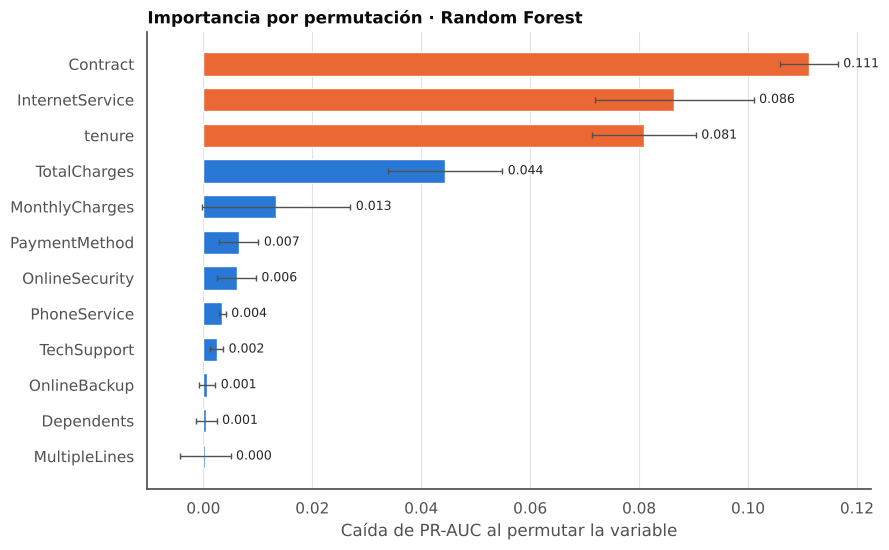

In [ ]:
perm = permutation_importance(MODELO_FINAL, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
importancia = pd.DataFrame({"media": perm.importances_mean, "sd": perm.importances_std}, index=X_test.columns)
importancia = importancia.sort_values("media").tail(12)
colores = [C["churn"] if i >= len(importancia) - 3 else C["no"] for i in range(len(importancia))]

fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(importancia.index, importancia["media"], xerr=importancia["sd"], color=colores, height=0.65,
        error_kw={"ecolor": C["tinta2"], "elinewidth": 1, "capsize": 2})
for i, (m, s) in enumerate(zip(importancia["media"], importancia["sd"])):
    ax.text(m + s + 0.001, i, f"{m:.3f}", va="center", fontsize=9)
ax.set_xlabel("Caída de PR-AUC al permutar la variable")
ax.set_title(f"Importancia por permutación · {GANADOR}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Dirección del efecto: *odds ratios* de la Regresión Logística

La importancia dice *cuánto* pesa una variable, no *hacia dónde* empuja. Los coeficientes de la Regresión Logística, convertidos a **odds ratio** (`exp(coeficiente)`), sí lo dicen: un valor mayor que 1 aumenta las probabilidades de abandono (naranja) y uno menor que 1 las reduce (azul). Las variables numéricas están estandarizadas, por lo que su odds ratio corresponde a un aumento de **una desviación estándar**; las binarias, al paso de 0 a 1.

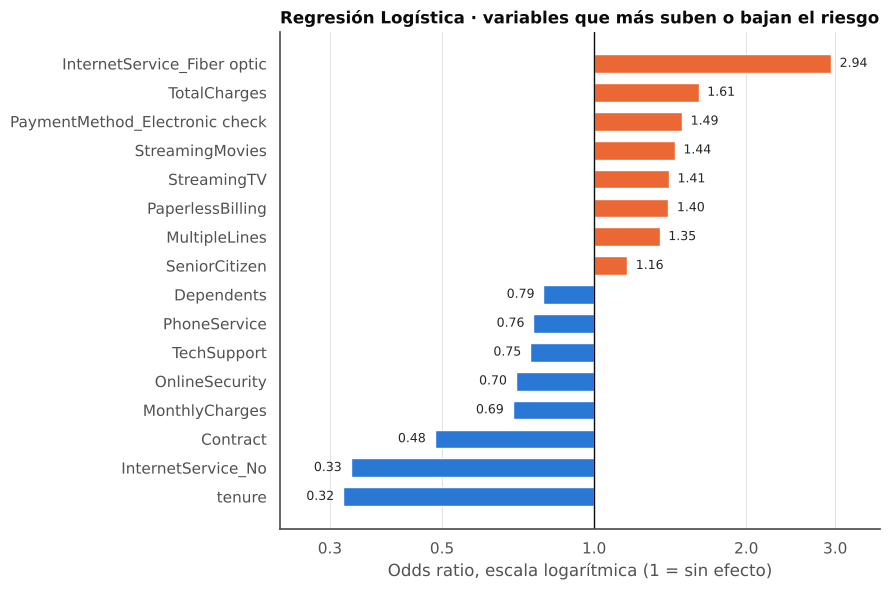

In [ ]:
lr_final = MODELOS["Regresión Logística"]
nombres_col = lr_final.named_steps["prep"].get_feature_names_out()
odds = pd.Series(np.exp(lr_final.named_steps["modelo"].coef_[0]), index=nombres_col).sort_values()
seleccion = pd.concat([odds.head(8), odds.tail(8)])
colores = [C["churn"] if v > 1 else C["no"] for v in seleccion]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(seleccion.index, seleccion.values - 1, left=1, color=colores, height=0.65)
ax.set_xscale("log")
for i, v in enumerate(seleccion.values):
    ax.text(v * (1.04 if v > 1 else 0.96), i, f"{v:.2f}", va="center", ha="left" if v > 1 else "right", fontsize=9)
ax.axvline(1, color=C["tinta"], linewidth=1)
ax.set_xlim(seleccion.min() * 0.75, seleccion.max() * 1.25)
ax.set_xticks([0.3, 0.5, 1, 2, 3])
ax.xaxis.set_major_formatter(mtick.ScalarFormatter())
ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_xlabel("Odds ratio, escala logarítmica (1 = sin efecto)")
ax.set_title("Regresión Logística · variables que más suben o bajan el riesgo")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Advertencia sobre la interpretación

`tenure`, `MonthlyCharges` y `TotalCharges` están fuertemente relacionadas entre sí (el total acumulado es, aproximadamente, antigüedad × cargo mensual), y varios servicios se contratan en conjunto. Con variables correlacionadas, **los coeficientes individuales pueden compensarse** entre sí y cambiar de signo respecto de lo que muestra el análisis exploratorio. Por eso las conclusiones sobre *qué perfiles* concentran el riesgo se apoyan principalmente en las tasas observadas de la Fase 2 y en la importancia por permutación, y los odds ratios se leen como apoyo y no como efecto causal.

## 5.8 Equidad por subgrupo (sesgos demográficos)

El informe identifica un riesgo ético: que el modelo asocie mayor riesgo a **adultos mayores** o a un **género** y que eso derive en condiciones comerciales desfavorables. Se audita el modelo final por subgrupo con tres lecturas:

- **Tasa de alertas:** qué proporción del grupo recibe una alerta.
- **Recall (TPR):** de los que realmente se van, cuántos se detectan.
- **Tasa de falsos positivos (FPR):** de los que se quedan, cuántos reciben alerta de todos modos.

Una diferencia en la tasa de alertas no es necesariamente injusta si el grupo realmente abandona más; las diferencias de **Recall y FPR** muestran si el modelo se equivoca más con un grupo que con otro.

,clientes,abandono real,tasa de alertas,Recall (TPR),FPR
grupo,,,,,
Adulto mayor,222,0.441,0.658,0.918,0.452
No adulto mayor,1187,0.233,0.366,0.772,0.244
Mujer,687,0.281,0.408,0.793,0.257
Hombre,722,0.251,0.417,0.829,0.279


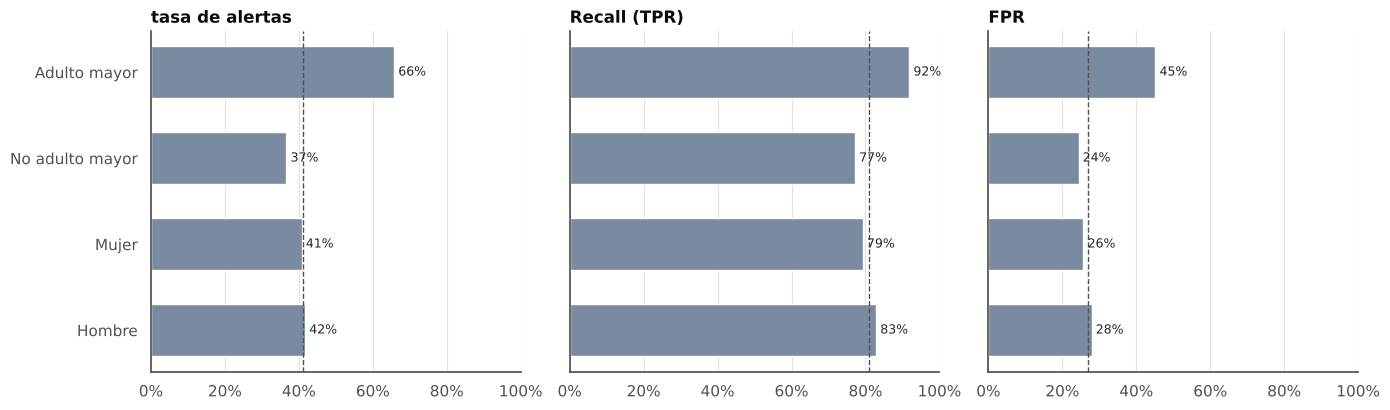

- **Edad:** los adultos mayores reciben alerta en el 66% de los casos, 1.8 veces la tasa del resto (37%). Parte se explica porque abandonan más (44% frente a 23%), pero también hay más falsos positivos: 45% de los adultos mayores que se quedarían recibe alerta, frente a 24%.
- **Género:** la diferencia es pequeña: 0.9 puntos en la tasa de alertas y 3.6 puntos en Recall.
- **Uso responsable:** la alerta debe servir para **priorizar contacto con beneficios de retención**, no para aplicar condiciones comerciales desfavorables a un segmento. Esto es especialmente importante en el caso de los adultos mayores.

In [ ]:
pred_final = (PROB_TEST[GANADOR] >= UMBRAL_FINAL).astype(int)
grupos = {
    "Adulto mayor": X_test["SeniorCitizen"].eq(1),
    "No adulto mayor": X_test["SeniorCitizen"].eq(0),
    "Mujer": X_test["gender"].eq(0),
    "Hombre": X_test["gender"].eq(1),
}
filas = []
for nombre, mascara in grupos.items():
    yr, yp = y_test[mascara.values].values, pred_final[mascara.values]
    filas.append({"grupo": nombre, "clientes": int(mascara.sum()), "abandono real": yr.mean(),
                  "tasa de alertas": yp.mean(), "Recall (TPR)": recall_score(yr, yp),
                  "FPR": ((yp == 1) & (yr == 0)).sum() / (yr == 0).sum()})
equidad = pd.DataFrame(filas).set_index("grupo")
display(equidad.round(3))

referencia = {"tasa de alertas": pred_final.mean(), "Recall (TPR)": recall_score(y_test, pred_final),
              "FPR": ((pred_final == 1) & (y_test.values == 0)).sum() / (y_test.values == 0).sum()}
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, columna in zip(ejes, ["tasa de alertas", "Recall (TPR)", "FPR"]):
    barras = ax.barh(equidad.index[::-1], equidad[columna][::-1], height=0.6,
                     color="#7a8aa0")
    ax.bar_label(barras, labels=[f"{v:.0%}" for v in equidad[columna][::-1]], padding=3, fontsize=9)
    ax.axvline(referencia[columna], color=C["tinta2"], linestyle="--", linewidth=1)
    ax.set_xlim(0, 1)
    ax.set_title(columna)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

mayor_, no_mayor_ = equidad.loc["Adulto mayor"], equidad.loc["No adulto mayor"]
mujer_, hombre_ = equidad.loc["Mujer"], equidad.loc["Hombre"]
display(Markdown("\n".join([
    f"- **Edad:** los adultos mayores reciben alerta en el {mayor_['tasa de alertas']:.0%} de los casos, {mayor_['tasa de alertas'] / no_mayor_['tasa de alertas']:.1f} veces la tasa del resto "
    f"({no_mayor_['tasa de alertas']:.0%}). Parte se explica porque abandonan más ({mayor_['abandono real']:.0%} frente a {no_mayor_['abandono real']:.0%}), pero también hay más falsos positivos: "
    f"{mayor_['FPR']:.0%} de los adultos mayores que se quedarían recibe alerta, frente a {no_mayor_['FPR']:.0%}.",
    f"- **Género:** la diferencia es pequeña: {abs(mujer_['tasa de alertas'] - hombre_['tasa de alertas']) * 100:.1f} puntos en la tasa de alertas y "
    f"{abs(mujer_['Recall (TPR)'] - hombre_['Recall (TPR)']) * 100:.1f} puntos en Recall.",
    "- **Uso responsable:** la alerta debe servir para **priorizar contacto con beneficios de retención**, no para aplicar condiciones comerciales desfavorables a un segmento. "
    "Esto es especialmente importante en el caso de los adultos mayores.",
])))

### ¿Aporta `gender` alguna ganancia predictiva?

El informe indica que se evaluará **excluir `gender`** si no mejora el modelo. Se reentrena el modelo final sin esa columna, con los mismos hiperparámetros y el mismo umbral, y se comparan las métricas en prueba.

In [ ]:
sin_genero = clone(MODELO_FINAL).fit(X_train.drop(columns="gender"), y_train)
prob_sin_genero = sin_genero.predict_proba(X_test.drop(columns="gender"))[:, 1]
comparacion_genero = pd.DataFrame({
    "con gender": metricas_clasif(y_test, PROB_TEST[GANADOR], UMBRAL_FINAL),
    "sin gender": metricas_clasif(y_test, prob_sin_genero, UMBRAL_FINAL),
}).T
comparacion_genero["Δ vs con gender"] = comparacion_genero["pr_auc"] - comparacion_genero.loc["con gender", "pr_auc"]
display(comparacion_genero.round(4))

dif_pr_genero = comparacion_genero.loc["con gender", "pr_auc"] - comparacion_genero.loc["sin gender", "pr_auc"]
GENERO_SE_EXCLUYE = bool(dif_pr_genero < 0.005)
display(Markdown(
    f"La diferencia de PR-AUC entre usar y no usar `gender` es de **{dif_pr_genero:+.4f}**. "
    + ("Como la ganancia es inferior a 0,005, **se recomienda excluir `gender`** del modelo desplegado: no aporta capacidad predictiva relevante y su exclusión reduce el riesgo de trato desigual."
       if GENERO_SE_EXCLUYE else
       "La ganancia es relevante, pero debe ponderarse contra el riesgo de trato desigual antes de mantenerla.")))

,recall,precision,f1,roc_auc,pr_auc,Δ vs con gender
con gender,0.8102,0.5215,0.6346,0.8467,0.6508,0.000
sin gender,0.8075,0.5234,0.6351,0.8462,0.6488,-0.002


La diferencia de PR-AUC entre usar y no usar `gender` es de **+0.0020**. Como la ganancia es inferior a 0,005, **se recomienda excluir `gender`** del modelo desplegado: no aporta capacidad predictiva relevante y su exclusión reduce el riesgo de trato desigual.

# Fase 6 · Despliegue (Deployment)

El resultado esperado del informe es «una función de puntuación de riesgo de fuga lista para apoyar decisiones de retención». La función recibe clientes en el **mismo formato del CSV original** y devuelve, para cada uno, su probabilidad de fuga, si debe recibir una alerta y un nivel de riesgo:

- **Alto:** probabilidad ≥ umbral del modelo (se emite alerta).
- **Medio:** entre la mitad del umbral y el umbral.
- **Bajo:** bajo la mitad del umbral.

## 6.1 Función de puntuación

In [ ]:
def puntuar_riesgo(datos, modelo=None, umbral=None):
    modelo = MODELO_FINAL if modelo is None else modelo
    umbral = UMBRAL_FINAL if umbral is None else umbral
    atributos = preparar_atributos(datos)
    prob = modelo.predict_proba(atributos)[:, 1]
    resultado = pd.DataFrame({"prob_fuga": prob}, index=datos.index)
    if "customerID" in datos.columns:
        resultado.insert(0, "customerID", datos["customerID"].values)
    resultado["alerta"] = prob >= umbral
    resultado["nivel_riesgo"] = pd.cut(prob, bins=[0, umbral / 2, umbral, 1.0001],
                                       labels=["Bajo", "Medio", "Alto"], right=False)
    return resultado

clientes_prueba = df_raw.loc[X_test.index]
puntajes = puntuar_riesgo(clientes_prueba)

print(f"Modelo: {GANADOR} · umbral de alerta: {UMBRAL_FINAL:.2f}")
print("\nLos 10 clientes con mayor riesgo de fuga en el conjunto de prueba:")
top10 = puntajes.sort_values("prob_fuga", ascending=False).head(10).join(
    clientes_prueba[["Contract", "tenure", "MonthlyCharges", "InternetService"]])
top10["prob_fuga"] = top10["prob_fuga"].map("{:.1%}".format)
display(top10.reset_index(drop=True))

Modelo: Random Forest · umbral de alerta: 0.48

Los 10 clientes con mayor riesgo de fuga en el conjunto de prueba:


,customerID,prob_fuga,alerta,nivel_riesgo,Contract,tenure,MonthlyCharges,InternetService
0,1820-TQVEV,98.2%,True,Alto,Month-to-month,1,69.55,Fiber optic
1,8375-DKEBR,98.1%,True,Alto,Month-to-month,1,69.60,Fiber optic
2,5542-TBBWB,97.9%,True,Alto,Month-to-month,1,69.90,Fiber optic
3,9804-ICWBG,97.9%,True,Alto,Month-to-month,1,69.90,Fiber optic
4,9248-OJYKK,97.7%,True,Alto,Month-to-month,1,76.45,Fiber optic
5,3716-BDVDB,97.4%,True,Alto,Month-to-month,1,69.10,Fiber optic
6,1069-XAIEM,97.1%,True,Alto,Month-to-month,1,85.05,Fiber optic
7,0679-IDSTG,97.0%,True,Alto,Month-to-month,1,69.25,Fiber optic
8,2514-GINMM,96.9%,True,Alto,Month-to-month,1,79.50,Fiber optic
9,2609-IAICY,96.8%,True,Alto,Month-to-month,1,77.15,Fiber optic


## 6.2 Validación de los niveles de riesgo

Un buen puntaje de riesgo debe ser **monótono**: a mayor nivel, mayor tasa real de abandono. Se compara el nivel asignado por el modelo con lo que realmente ocurrió en los clientes de prueba.

,clientes,tasa_real
nivel_riesgo,,
Bajo,532,3.8%
Medio,296,17.2%
Alto,581,52.2%


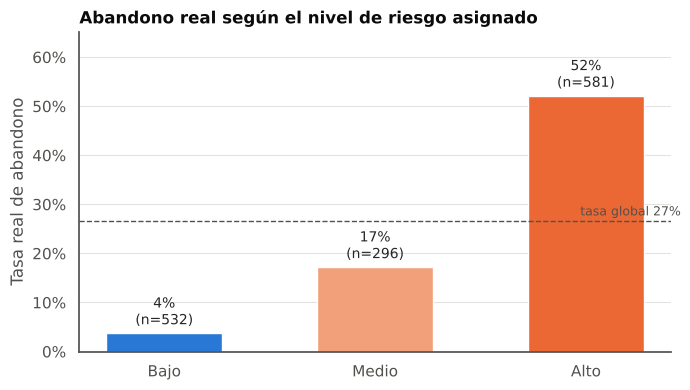

In [ ]:
validacion = puntajes.assign(abandono_real=y_test.values).groupby("nivel_riesgo", observed=True).agg(
    clientes=("abandono_real", "size"), tasa_real=("abandono_real", "mean")).reindex(["Bajo", "Medio", "Alto"])
display(validacion.assign(tasa_real=validacion["tasa_real"].map("{:.1%}".format)))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(validacion.index.astype(str), validacion["tasa_real"],
                color=[C["no"], "#f2a07a", C["churn"]], width=0.55)
ax.bar_label(barras, labels=[f"{v:.0%}\n(n={n})" for v, n in zip(validacion["tasa_real"], validacion["clientes"])],
             padding=3, fontsize=10)
ax.axhline(y_test.mean(), color=C["tinta2"], linestyle="--", linewidth=1)
ax.text(2.45, y_test.mean() + 0.012, f"tasa global {y_test.mean():.0%}", ha="right", fontsize=9, color=C["tinta2"])
ax.set_ylim(0, validacion["tasa_real"].max() * 1.25)
ax.set_title("Abandono real según el nivel de riesgo asignado")
ax.set_ylabel("Tasa real de abandono")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 6.3 Curva de ganancia acumulada: ¿a cuántos clientes conviene contactar?

Es el gráfico que más le sirve al área de retención. Se ordena a los clientes del **más riesgoso al menos riesgoso** y se mide qué porcentaje de las fugas reales queda cubierto al contactar al primer 10 %, 20 %, 30 %… de la lista. La diagonal es lo que se lograría contactando al azar; cuanto más se aleja la curva hacia arriba, más eficiente es la campaña.

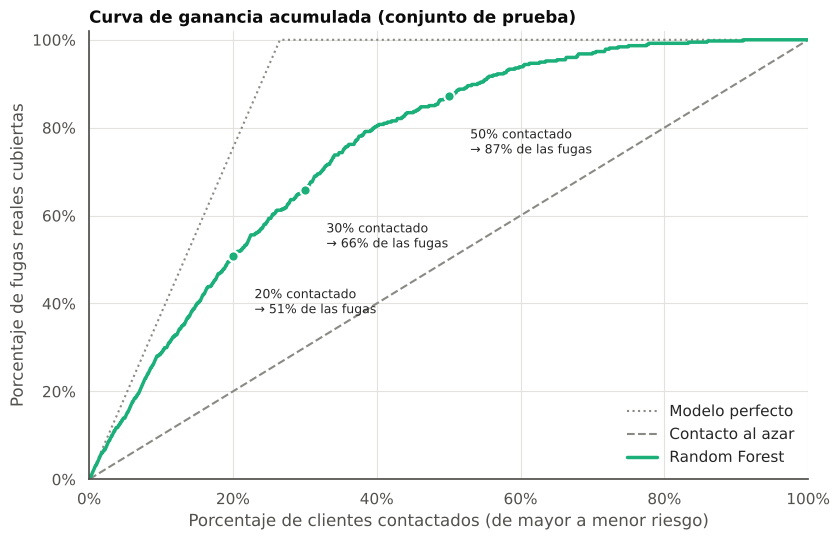

,clientes,fugas,tasa de abandono,fugas acumuladas,lift
decil,,,,,
1,141,107,0.759,0.286,2.859
2,141,83,0.589,0.508,2.218
3,141,56,0.397,0.658,1.496
4,141,55,0.390,0.805,1.470
5,141,25,0.177,0.872,0.668
6,141,25,0.177,0.939,0.668
7,141,12,0.085,0.971,0.321
8,141,8,0.057,0.992,0.214
9,141,2,0.014,0.997,0.053


In [ ]:
orden = np.argsort(-puntajes["prob_fuga"].values)
abandonos_ordenados = y_test.values[orden]
contactados = np.arange(1, len(orden) + 1) / len(orden)
capturados = np.cumsum(abandonos_ordenados) / abandonos_ordenados.sum()
ideal = np.minimum(contactados / y_test.mean(), 1.0)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(contactados, ideal, color=C["base"], linestyle=":", linewidth=1.5, label="Modelo perfecto")
ax.plot(contactados, contactados, color=C["base"], linestyle="--", linewidth=1.5, label="Contacto al azar")
ax.plot(contactados, capturados, color=COLOR_MODELO[GANADOR], linewidth=2.5, label=GANADOR)
for p in (0.2, 0.3, 0.5):
    valor = capturados[int(p * len(orden)) - 1]
    ax.scatter([p], [valor], color=COLOR_MODELO[GANADOR], s=55, zorder=5, edgecolor="white", linewidth=1.5)
    ax.annotate(f"{p:.0%} contactado\n→ {valor:.0%} de las fugas", (p, valor), xytext=(p + 0.03, valor - 0.13), fontsize=9)
ax.set_xlabel("Porcentaje de clientes contactados (de mayor a menor riesgo)")
ax.set_ylabel("Porcentaje de fugas reales cubiertas")
ax.set_title("Curva de ganancia acumulada (conjunto de prueba)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

deciles = pd.DataFrame({"decil": np.minimum((np.arange(len(orden)) * 10) // len(orden), 9) + 1, "abandono": abandonos_ordenados})
tabla_deciles = deciles.groupby("decil")["abandono"].agg(clientes="size", fugas="sum")
tabla_deciles["tasa de abandono"] = tabla_deciles["fugas"] / tabla_deciles["clientes"]
tabla_deciles["fugas acumuladas"] = tabla_deciles["fugas"].cumsum() / tabla_deciles["fugas"].sum()
tabla_deciles["lift"] = tabla_deciles["tasa de abandono"] / y_test.mean()
display(tabla_deciles.round(3))

## 6.4 Guardado del modelo

El modelo final, su umbral y las columnas esperadas se guardan en un único archivo para poder reutilizarlo sin reentrenar. Se verifica que el modelo recargado produce **exactamente** las mismas probabilidades.

In [ ]:
ARCHIVO_MODELO = "/content/modelo_churn_telco.joblib"
joblib.dump({"modelo": MODELO_FINAL, "umbral": UMBRAL_FINAL, "nombre": GANADOR,
             "columnas": list(X.columns), "version_sklearn": sklearn.__version__}, ARCHIVO_MODELO)

paquete = joblib.load(ARCHIVO_MODELO)
prob_recargado = paquete["modelo"].predict_proba(X_test)[:, 1]
print(f"Archivo guardado: {ARCHIVO_MODELO}")
print(f"Modelo: {paquete['nombre']} · umbral {paquete['umbral']:.3f} · scikit-learn {paquete['version_sklearn']}")
print(f"Probabilidades idénticas tras recargar: {bool(np.allclose(prob_recargado, PROB_TEST[GANADOR]))}")

Archivo guardado: /content/modelo_churn_telco.joblib
Modelo: Random Forest · umbral 0.484 · scikit-learn 1.9.1
Probabilidades idénticas tras recargar: True


# Fase 7 · Conclusiones

## 7.1 Resumen de resultados

Las cifras siguientes se calculan a partir de la ejecución actual.

In [ ]:
cumplidos = int((criterios["cumple"] == "✅").sum())
fallidos = criterios.loc[criterios["cumple"] == "❌", "criterio"].tolist()
top_vars = list(importancia.sort_values("media", ascending=False).index[:3])
cobertura30 = capturados[int(0.3 * len(orden)) - 1]
texto_dif = "; ".join(
    f"{i.split(' − ')[0]} ({fila['diferencia observada']:+.3f}, IC 95 % {fila['IC 95 %']}) "
    + ("sí se distingue del azar" if fila["distinguible del azar"] == "sí" else "no se distingue del azar")
    for i, fila in tabla_dif.iterrows())
p_rl = (remuestreos["Regresión Logística"]["Recall"] >= RECALL_OBJETIVO).mean()
p_gan = (remuestreos[GANADOR]["Recall"] >= RECALL_OBJETIVO).mean()

resumen_final = pd.DataFrame({
    "Modelo": [GANADOR], "Umbral": [round(UMBRAL_FINAL, 3)],
    "Recall": [round(rec_f, 3)], "Precisión": [round(pre_f, 3)], "F1": [round(f1_f, 3)],
    "ROC-AUC": [round(final["roc_auc"], 3)], "PR-AUC": [round(final["pr_auc"], 3)],
    "Criterios cumplidos": [f"{cumplidos} de {len(criterios)}"],
}).set_index("Modelo")
display(resumen_final)

conclusiones = [
    f"1. **Modelo recomendado: {GANADOR}** con umbral {UMBRAL_FINAL:.2f}. En prueba detecta el {rec_f:.0%} de las fugas, con una precisión de {pre_f:.0%} y un F1 de {f1_f:.3f}, "
    f"muy por encima del modelo base (Recall {metricas_base['recall']:.0%}, F1 {metricas_base['f1']:.2f}).",
    f"2. **Criterios de éxito:** se cumplen {cumplidos} de {len(criterios)}." + (f" No se cumple: {'; '.join(fallidos)}." if fallidos else " Se cumplen todos."),
    f"3. **H1 {'se confirma' if H1_CONFIRMADA else 'se rechaza'}:** los ensambles superan a la Regresión Logística por {dif_f1:+.3f} de F1 con la misma regla de decisión "
    f"(se exigía ≥ {MEJORA_H1_F1:.2f}). " + ("La ventaja de los ensambles es pequeña: la mayor parte de la señal ya la captura el modelo lineal." if not H1_CONFIRMADA else "Hay interacciones no lineales que el modelo lineal no captura."),
    f"4. **H2 {'se confirma' if H2_CONFIRMADA else 'se rechaza'}:** ponderar las clases y bajar el umbral a {UMBRAL_H2:.2f} eleva el Recall de {recall_inicial:.2f} a {recall_h2:.2f} ({mejora_h2 * 100:+.0f} puntos), a costa de precisión.",
    f"5. **Las diferencias entre modelos son pequeñas.** Frente a la Regresión Logística, en F1 (cada modelo con su umbral ajustado): {texto_dif}. "
    f"Con el margen de error de la prueba, el Recall de {GANADOR} cumple el objetivo de {RECALL_OBJETIVO} en el {p_gan:.0%} de los remuestreos y el de la Regresión Logística en el {p_rl:.0%}. "
    "La elección entre modelos debe pesar también interpretabilidad y costo de mantenimiento.",
    f"6. **Qué determina el riesgo:** las variables de mayor importancia son {', '.join(f'`{v}`' for v in top_vars)}. En el análisis exploratorio, el abandono fue de {mtm:.0%} con contrato mensual frente a {dos:.0%} con contrato de dos años.",
    f"7. **Valor para retención:** contactar solo al 30% de los clientes con mayor riesgo cubre el {cobertura30:.0%} de las fugas reales; el primer decil tiene un abandono {tabla_deciles.loc[1, 'lift']:.1f} veces superior al promedio.",
    f"8. **Equidad:** los adultos mayores reciben alertas {mayor_['tasa de alertas'] / no_mayor_['tasa de alertas']:.1f} veces más seguido que el resto y con más falsos positivos; el género casi no influye y " + ("se recomienda excluirlo del modelo desplegado." if GENERO_SE_EXCLUYE else "su exclusión debe evaluarse."),
]
display(Markdown("\n\n".join(conclusiones)))

,Umbral,Recall,Precisión,F1,ROC-AUC,PR-AUC,Criterios cumplidos
Modelo,,,,,,,
Random Forest,0.484,0.81,0.522,0.635,0.847,0.651,6 de 7


1. **Modelo recomendado: Random Forest** con umbral 0.48. En prueba detecta el 81% de las fugas, con una precisión de 52% y un F1 de 0.635, muy por encima del modelo base (Recall 29%, F1 0.29).

2. **Criterios de éxito:** se cumplen 6 de 7. No se cumple: Precisión operativa.

3. **H1 se rechaza:** los ensambles superan a la Regresión Logística por +0.023 de F1 con la misma regla de decisión (se exigía ≥ 0.05). La ventaja de los ensambles es pequeña: la mayor parte de la señal ya la captura el modelo lineal.

4. **H2 se confirma:** ponderar las clases y bajar el umbral a 0.40 eleva el Recall de 0.56 a 0.87 (+31 puntos), a costa de precisión.

5. **Las diferencias entre modelos son pequeñas.** Frente a la Regresión Logística, en F1 (cada modelo con su umbral ajustado): Random Forest (+0.020, IC 95 % [+0.001, +0.039]) sí se distingue del azar; Gradient Boosting (+0.009, IC 95 % [-0.009, +0.027]) no se distingue del azar. Con el margen de error de la prueba, el Recall de Random Forest cumple el objetivo de 0.78 en el 93% de los remuestreos y el de la Regresión Logística en el 52%. La elección entre modelos debe pesar también interpretabilidad y costo de mantenimiento.

6. **Qué determina el riesgo:** las variables de mayor importancia son `Contract`, `InternetService`, `tenure`. En el análisis exploratorio, el abandono fue de 43% con contrato mensual frente a 3% con contrato de dos años.

7. **Valor para retención:** contactar solo al 30% de los clientes con mayor riesgo cubre el 66% de las fugas reales; el primer decil tiene un abandono 2.9 veces superior al promedio.

8. **Equidad:** los adultos mayores reciben alertas 1.8 veces más seguido que el resto y con más falsos positivos; el género casi no influye y se recomienda excluirlo del modelo desplegado.

## 7.2 Recomendaciones para el área de retención

Las siguientes acciones se derivan de los patrones observados. Son **asociaciones, no causas**: antes de escalarlas conviene validarlas con un piloto controlado (grupo contactado frente a grupo de control).

- **Usar el puntaje como lista de prioridad de contacto**, no como decisión automática. El nivel *Alto* concentra la mayor parte de las fugas y es donde conviene invertir primero.
- **Ofrecer migración a contrato anual o bianual** a clientes con contrato mensual, sobre todo en sus primeros meses: es el perfil con mayor abandono.
- **Reforzar el soporte técnico y la seguridad en línea** como parte de los planes de fibra óptica, que concentran más abandono que el DSL.
- **Incentivar el pago automático** a quienes pagan con cheque electrónico, medio asociado a mayor abandono.
- **Priorizar el acompañamiento en los primeros 12 meses**, periodo en que el riesgo es más alto.

## 7.3 Limitaciones

- **Datos de ejemplo:** el dataset corresponde a una muestra pública de IBM (2018). Antes de usarlo en una empresa real chilena habría que reentrenar con sus propios datos.
- **Una sola fotografía en el tiempo:** `Churn` indica el abandono del último mes, sin estacionalidad ni contexto económico. No se pudo validar con una partición temporal.
- **Sin costos reales:** el informe no incluye el costo de una campaña ni el valor de retener a un cliente, por lo que el umbral se eligió con criterios de Recall y F1 y no con una función de costo-beneficio.
- **Tamaño de la prueba:** con 1.409 clientes, las métricas tienen un margen de error de varios puntos (ver intervalos de bootstrap en la sección 5.4).
- **Variables correlacionadas:** `tenure`, `MonthlyCharges` y `TotalCharges` se relacionan entre sí; los coeficientes individuales deben leerse con cautela.

## 7.4 Trabajo futuro

- Definir el umbral con una **función de costo-beneficio** una vez que la empresa entregue el costo por contacto y el valor de retención.
- **Calibrar las probabilidades** (por ejemplo con `CalibratedClassifierCV`) para que 0,70 signifique realmente 70 % de riesgo.
- Explicar predicciones individuales con **SHAP** para que el ejecutivo de retención sepa por qué un cliente aparece en la lista.
- **Monitorear** el modelo en producción (deriva de datos y de desempeño) y reentrenarlo periódicamente.

## 7.5 Consideraciones éticas y de privacidad

- **Protección de datos personales (Ley N.º 21.719):** el dataset es público y solo contiene códigos sintéticos (`customerID`) sin datos de identidad directa. Si se aplicara sobre una base real de clientes en Chile, deberá regirse por la Ley N.º 21.719: seudonimización de identificadores (RUT, nombre, correo), minimización de datos, base de licitud, transparencia en el tratamiento para fidelización y resguardo de los derechos del titular (acceso, oposición y revisión humana ante decisiones automatizadas relevantes).
- **Sesgos demográficos:** el modelo no debe usarse para aplicar condiciones comerciales desfavorables por edad o género. Se audita por subgrupo (sección 5.8) y se recomienda excluir `gender`.
- **Sesgo temporal y de muestreo:** al ser una fotografía estática, las conclusiones reflejan patrones de ese corte de datos y requieren monitoreo periódico.

## Referencias

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
2. Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc.
3. IBM Sample Data Sets. (2018). *Telco Customer Churn* [Dataset]. Kaggle. https://www.kaggle.com/datasets/blastchar/telco-customer-churn
4. República de Chile. (2024). *Ley N.º 21.719: Regula la protección y el tratamiento de los datos personales y crea la Agencia de Protección de Datos Personales*. Biblioteca del Congreso Nacional de Chile.
5. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.

In [ ]:
print("Versiones usadas en esta ejecución")
print(f"  pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · seaborn {sns.__version__} · matplotlib {mpl.__version__}")
print(f"  semilla = {SEED} · partición 80/20 estratificada · validación cruzada de 5 pliegues")

Versiones usadas en esta ejecución
  pandas 3.0.5 · numpy 2.5.3 · scikit-learn 1.9.1 · seaborn 0.13.2 · matplotlib 3.11.2
  semilla = 42 · partición 80/20 estratificada · validación cruzada de 5 pliegues
